# Decoder tuning — ทดสอบข้อเสนอปรับ spotting.json

เป้าหมาย: เทียบ baseline กับค่าที่เสนอโดยใช้ข้อมูลจริงและ landmarks ชุดเดียวกัน ตรวจว่าลด insertion แต่เพิ่ม deletion หรือไม่ เริ่มคลิป **ฉัน → แอบ → ชอบ → คุณ**

ผลรอบนี้เป็น **development diagnostics** ไม่ใช่ held-out test หลังดูข้อผิดพลาดจากคลิปนี้แล้ว ห้ามใช้ผลดีขึ้นหนึ่งคลิปอ้างว่าแก้ระบบได้ทั่วไป

ค่าทั้งหมด override เฉพาะ pipe.spot ในหน่วยความจำ ไม่แก้ models/spotting.json, weights, bank หรือ rule dictionary และปิด symbolic เพื่อแยกผลการจูน decoder

## 1. ข้อเสนอที่ตรวจเทียบโค้ดแล้ว

| ประเด็น | พฤติกรรมจริง |
|---|---|
| exact_rescore | เรียก encoder จริงมา rescore เมื่อมี span head; อาจช้าขึ้นและไม่รับประกันว่าดีขึ้น |
| CSLS | ต้องมี hub vector; เครื่องนี้ไม่มี models/hub.npy จึง block เคสนี้ ไม่รันแบบไม่มีผลแล้วเรียกว่าเปิดแล้ว |
| freq_gamma | เพิ่มคะแนนจาก prior ความถี่ ไม่ได้ลดคะแนนคำที่พบบ่อย |
| alignment_score_cut | metadata จากการสร้าง bank ใน scripts/eval.py ไม่ใช่ runtime threshold |
| p_sign_min | ใช้ร่วมเงื่อนไข short/nullish ใน postprocess ไม่ใช่ตัดทุกคำที่ต่ำกว่า threshold |
| min_len / min_frames | อาจลดคำแทรก แต่ทำท่าสั้นจริงหาย ต้องวัด deletion |
| grammar | คงกฎเดิม ทดลองน้ำหนักอย่างเดียว ไม่แต่งกฎจากเฉลยคลิปนี้ |
| fingerspelling | alphabet=off อยู่แล้ว จึงไม่จูน threshold สะกดนิ้วในรอบนี้ |

ไม่ลบตัวอย่างจาก bank โดยอาศัยคะแนนอย่างเดียว ต้องตรวจป้ายจริงก่อน

In [1]:
from pathlib import Path
import sys,importlib
ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'modules/pipeline.py').exists()),None)
if ROOT is None:raise FileNotFoundError('เปิดภายใน repository')
HERE=ROOT/'Boom/phase2.1/05_decoder_tuning';sys.path.insert(0,str(HERE))
import decoder_experiment as de
importlib.reload(de)
ex=de.ex;ex.setup()
ex.show_table(ex.environment(),'**ตรวจ:** ใช้ venv-sign2say และ MediaPipe runtime แยกที่แก้ crash แล้ว')

,component,value
0,python,"3.11.8 (main, Apr 19 2025, 22:30:49) [Clang 14.0.3 (clang-1403.0.22.14.1)]"
1,executable,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/venv-sign2say/bin/python
2,platform,macOS-26.2-arm64-arm-64bit
3,torch,2.14.1
4,onnxruntime,1.23.2
5,providers,"['CoreMLExecutionProvider', 'AzureExecutionProvider', 'CPUExecutionProvider']"
6,mediapipe,1.1.0
7,project_imports,OK
8,notebook_kernel,/Users/thawaphorn/anaconda3/bin/python


**ตรวจ:** ใช้ venv-sign2say และ MediaPipe runtime แยกที่แก้ crash แล้ว

## 2. แผนแยกพารามิเตอร์

หนึ่งตัวแปรต่อเคสช่วยแยกว่าอะไรมีผล ชุด combined_without_csls เป็นการทดสอบข้อเสนอร่วมกันโดยตัด CSLS ที่ยังไม่มีข้อมูลรองรับออกอย่างชัดเจน ไม่ใช่ชุดเต็มจากเอกสาร

In [2]:
ex.show_table(de.plan(),'**status:** blocked ไม่ใช่ผลลบ แต่เป็น prerequisite ที่ขาด. effective_config บันทึกครบ รวม post fields เดิมที่ไม่ได้แก้')

,case,changes,status,effective_config
0,baseline,{},ready,"{""lens"": [8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48], ""stride"": 4, ""min_inside"": 0.6, ""delta"": 0..."
1,activity060,"{""act_thr"": 0.6}",ready,"{""lens"": [8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48], ""stride"": 4, ""min_inside"": 0.6, ""delta"": 0..."
2,min_len16,"{""min_len"": 16}",ready,"{""lens"": [8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48], ""stride"": 4, ""min_inside"": 0.6, ""delta"": 0..."
3,exact_rescore,"{""exact_rescore"": true}",ready,"{""lens"": [8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48], ""stride"": 4, ""min_inside"": 0.6, ""delta"": 0..."
4,post_frames12,"{""post"": {""min_frames"": 12}}",ready,"{""lens"": [8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48], ""stride"": 4, ""min_inside"": 0.6, ""delta"": 0..."
5,post_psign070,"{""post"": {""p_sign_min"": 0.7}}",ready,"{""lens"": [8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48], ""stride"": 4, ""min_inside"": 0.6, ""delta"": 0..."
6,grammar070,"{""grammar_rerank_weight"": 0.7}",ready,"{""lens"": [8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48], ""stride"": 4, ""min_inside"": 0.6, ""delta"": 0..."
7,stride2,"{""stride"": 2}",ready,"{""lens"": [8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48], ""stride"": 2, ""min_inside"": 0.6, ""delta"": 0..."
8,csls015,"{""csls_alpha"": 0.15}",blocked: models/hub.npy missing,"{""lens"": [8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48], ""stride"": 4, ""min_inside"": 0.6, ""delta"": 0..."
9,combined_without_csls,"{""act_thr"": 0.6, ""min_len"": 16, ""exact_rescore"": true, ""grammar_rerank_weight"": 0.7, ""post"": {""m...",ready,"{""lens"": [8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48], ""stride"": 4, ""min_inside"": 0.6, ""delta"": 0..."


**status:** blocked ไม่ใช่ผลลบ แต่เป็น prerequisite ที่ขาด. effective_config บันทึกครบ รวม post fields เดิมที่ไม่ได้แก้

## 3. เลือกคลิปและเคสที่จะรัน

ผล sweep บน 6 คลิปถูกรันไว้แล้วจึงตั้ง RUN=False เพื่อเปิดดูได้ทันที เปลี่ยน True เพื่อรันใหม่ หรือใช้ CASES=list(de.CASES) และ VIDEOS=[p.name for p in ex.videos()] เพื่อรันแยกทุกตัวบน 6 คลิป

การสกัดวิดีโอมี cache ตาม hash คลิป, model, extractor code และ MediaPipe version; ไม่ reuse ข้ามเงื่อนไขเหล่านี้ การรันใหม่บันทึกโฟลเดอร์เวลาใหม่ ไม่เขียนทับผลเดิม

In [3]:
RUN = False
CASES = list(de.CASES)
VIDEOS = [p.name for p in ex.videos()]
if RUN:
    de.launch(CASES,VIDEOS)
directory,metrics,segments,candidates=de.results()
ex.show_table(__import__('pandas').DataFrame([ex.read(directory/'manifest.json')]).T,
    '**Provenance:** ดู configs, hashes, blocked cases และเวอร์ชัน runtime ก่อนเปรียบเทียบ; ดึงเฉพาะ run ที่จบแล้ว')

,0
created,20261019_153342
scope,development diagnostics; not held-out test
configs,"{'baseline': {'lens': [8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48], 'stride': 4, 'min_inside': 0...."
blocked,{'csls015': 'missing hub; do not silently run alpha with no effect'}
symbolic_weight,0
alphabet,off
use_llm,False
hashes,"{'models/spotting.json': '1f550529879a5be136f9da1448d8f1b7a6945aba8f2a02eaf115205cbc9a2bcf', 'mo..."
mediapipe,1.1.0
python,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/venv-sign2say/bin/python


**Provenance:** ดู configs, hashes, blocked cases และเวอร์ชัน runtime ก่อนเปรียบเทียบ; ดึงเฉพาะ run ที่จบแล้ว

## 4. ผลเทียบจริงและข้อผิดพลาด S/D/I

WER ใช้ชื่อไฟล์ที่ผู้ใช้ยืนยันเป็นข้อความเฉลย แล้วตัดคำด้วย newmm เหมือนกันทั้งสองฝั่ง ไม่ใช่ gloss WER ที่ยืนยันขอบเขตครบ. proposed_gloss_WER ในไฟล์เต็มแยกไว้ต่างหาก

Segment F1 และ temporal Recall ยังไม่มีเฉลยเวลา จึงไม่สร้างตัวเลขขึ้นมา การจับคู่คำด้วย edit distance ไม่ใช่หลักฐานว่าท่าอยู่ตรง timestamp นั้น

,video,mode,WER,token_accuracy,substitutions,deletions,insertions,n_pred,count_error,inference_s,prediction
0,ฉันยังลืมคุณไม่ได้.MOV,baseline,1.333,0.000,6,0,2,8,2,2.878,ยาย | ไป | คุณ | ชอบ | ญาติ | เป็น | อย่า | เกิด
1,ฉันยังลืมคุณไม่ได้.MOV,activity060,1.333,0.000,6,0,2,8,2,2.520,ยาย | ไป | คุณ | ชอบ | ญาติ | เป็น | อย่า | เกิด
2,ฉันยังลืมคุณไม่ได้.MOV,min_len16,1.333,0.000,6,0,2,8,2,2.219,ยาย | ไป | คุณ | ชอบ | ญาติ | เป็น | อย่า | เกิด
3,ฉันยังลืมคุณไม่ได้.MOV,exact_rescore,1.167,0.167,5,0,2,8,2,5.359,ถูก | ลูก | อย่า | ฉัน | ถูก | ตลาด | อย่า | ได้
4,ฉันยังลืมคุณไม่ได้.MOV,post_frames12,1.333,0.000,6,0,2,8,2,2.547,ยาย | ไป | คุณ | ชอบ | ญาติ | เป็น | อย่า | เกิด
5,ฉันยังลืมคุณไม่ได้.MOV,post_psign070,1.333,0.000,6,0,2,8,2,2.598,ยาย | ไป | คุณ | ชอบ | ญาติ | เป็น | อย่า | เกิด
6,ฉันยังลืมคุณไม่ได้.MOV,grammar070,1.333,0.000,6,0,2,8,2,2.562,ยาย | ไป | คุณ | ชอบ | ญาติ | เป็น | อย่า | เกิด
7,ฉันยังลืมคุณไม่ได้.MOV,stride2,1.333,0.000,6,0,2,8,2,2.890,แฟน | ไป | คุณ | ชอบ | ญาติ | เป็น | อย่า | เกิด
8,ฉันยังลืมคุณไม่ได้.MOV,combined_without_csls,1.167,0.167,5,0,2,8,2,4.657,ถูก | ลูก | อย่า | ฉัน | ถูก | ตลาด | อย่า | ได้
9,ฉันแอบชอบคุณ.MOV,baseline,2.000,0.000,4,0,4,8,4,2.446,แฟน | แต่งงาน | เกิด | เป็น | แฟน | แต่งงาน | ข้าว | ถาม


**อ่านผล:** WER ต่ำลงต้องตรวจ S/D/I ด้วย เพราะลดคำแทรกอาจเพิ่มคำตกหล่น; inference_s ไม่รวม extraction/model loading และเป็น single run

,video,mode,delta_WER,delta_deletions,delta_insertions,delta_n_pred,delta_inference_s
0,ฉันยังลืมคุณไม่ได้.MOV,baseline,0.000,0,0,0,0.000
1,ฉันยังลืมคุณไม่ได้.MOV,activity060,0.000,0,0,0,-0.358
2,ฉันยังลืมคุณไม่ได้.MOV,min_len16,0.000,0,0,0,-0.659
3,ฉันยังลืมคุณไม่ได้.MOV,exact_rescore,-0.167,0,0,0,2.481
4,ฉันยังลืมคุณไม่ได้.MOV,post_frames12,0.000,0,0,0,-0.332
5,ฉันยังลืมคุณไม่ได้.MOV,post_psign070,0.000,0,0,0,-0.280
6,ฉันยังลืมคุณไม่ได้.MOV,grammar070,0.000,0,0,0,-0.316
7,ฉันยังลืมคุณไม่ได้.MOV,stride2,0.000,0,0,0,0.012
8,ฉันยังลืมคุณไม่ได้.MOV,combined_without_csls,-0.167,0,0,0,1.779
9,ฉันแอบชอบคุณ.MOV,baseline,0.000,0,0,0,0.000


**Delta = variant − baseline:** ไม่ใช้ผลคลิปเดียวเลือก production config; ชุดนี้เป็น development หลังตรวจปัญหาแล้ว

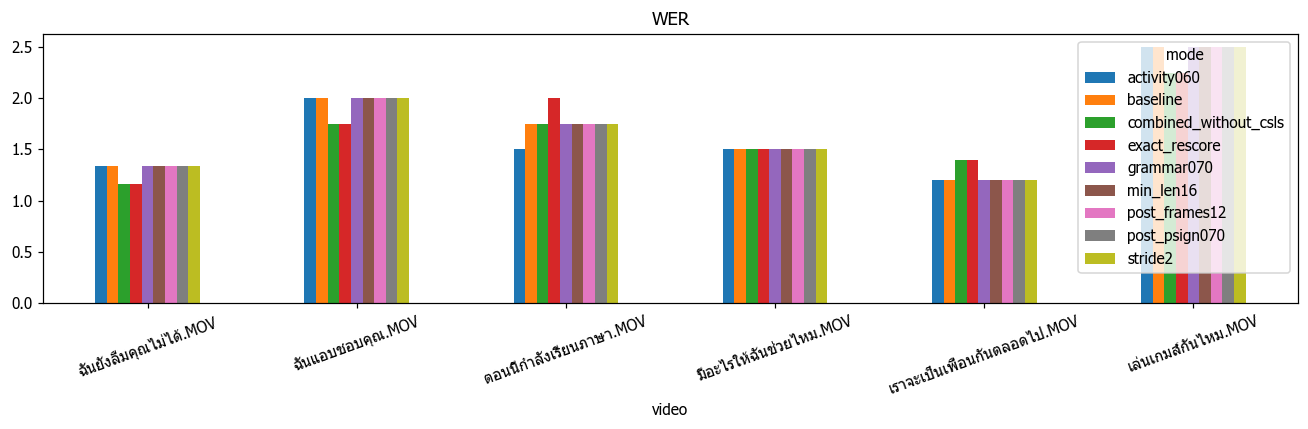

**WER:** เทียบแต่ละ setting บนคลิปเดียวกันและ landmarks ชุดเดียวกัน

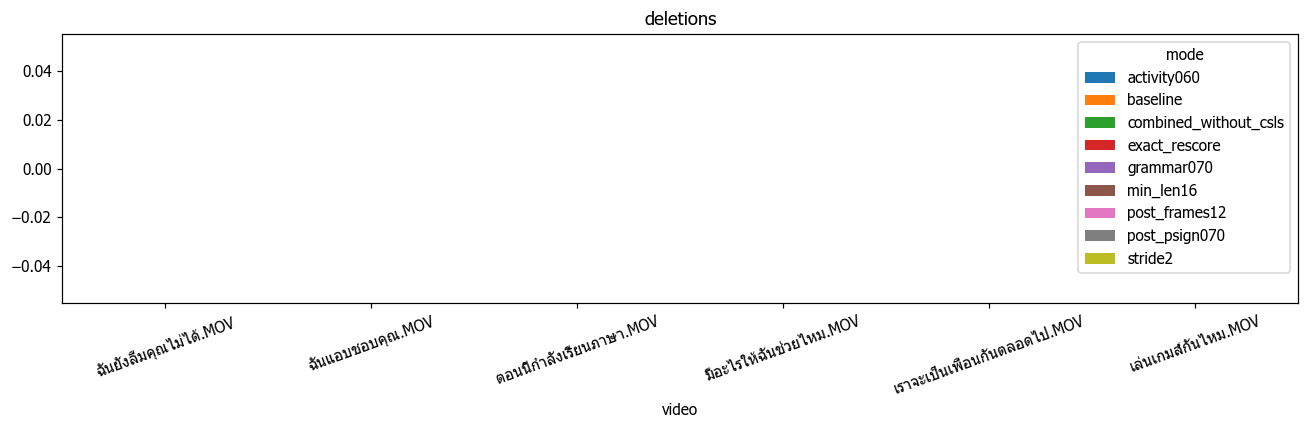

**deletions:** เทียบแต่ละ setting บนคลิปเดียวกันและ landmarks ชุดเดียวกัน

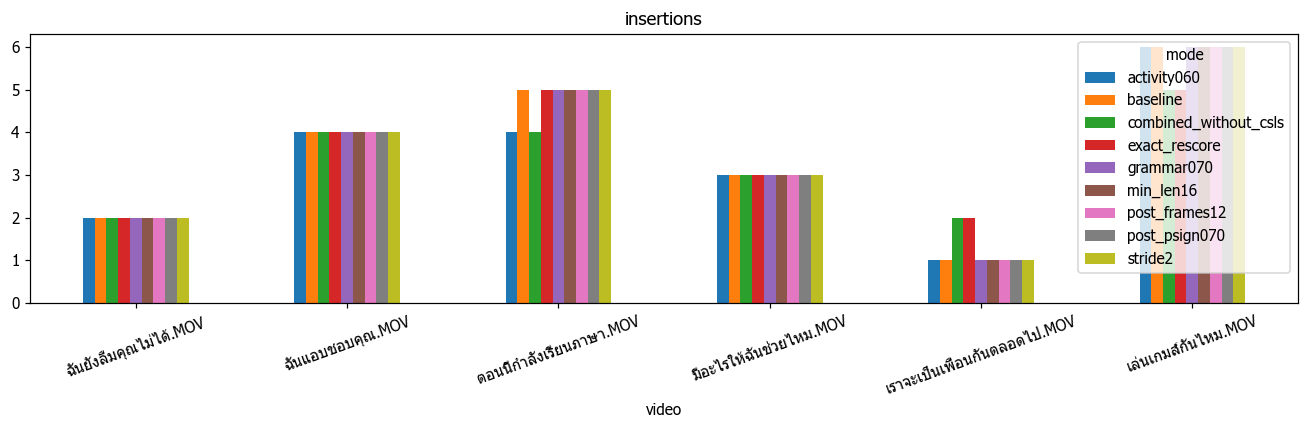

**insertions:** เทียบแต่ละ setting บนคลิปเดียวกันและ landmarks ชุดเดียวกัน

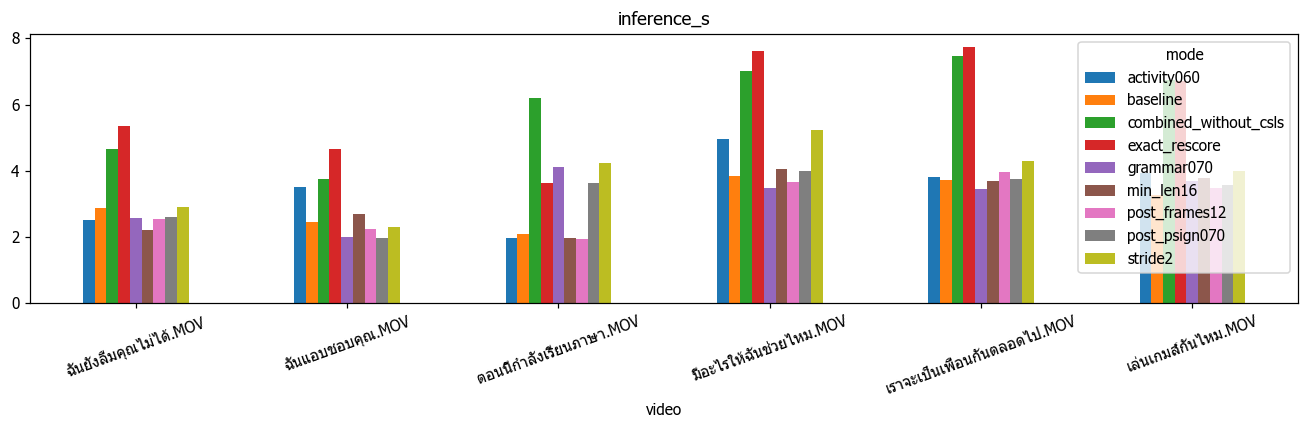

**inference_s:** เทียบแต่ละ setting บนคลิปเดียวกันและ landmarks ชุดเดียวกัน

,video,mode,segment,t0,t1,word,status,p_correct
0,ฉันยังลืมคุณไม่ได้.MOV,baseline,0,0.800,2.720,ยาย,uncertain,0.099
1,ฉันยังลืมคุณไม่ได้.MOV,baseline,1,2.880,3.840,ไป,uncertain,0.120
2,ฉันยังลืมคุณไม่ได้.MOV,baseline,2,3.840,5.280,คุณ,unknown,0.058
3,ฉันยังลืมคุณไม่ได้.MOV,baseline,3,5.280,5.920,ชอบ,uncertain,0.524
4,ฉันยังลืมคุณไม่ได้.MOV,baseline,4,6.560,8.480,ญาติ,uncertain,0.272
...,...,...,...,...,...,...,...,...
452,เล่นเกมส์กันไหม.MOV,combined_without_csls,4,7.360,8.480,ได้,unknown,0.045
453,เล่นเกมส์กันไหม.MOV,combined_without_csls,5,8.480,9.760,ถูก,accepted,0.805
454,เล่นเกมส์กันไหม.MOV,combined_without_csls,6,11.520,12.320,ญาติ,uncertain,0.096
455,เล่นเกมส์กันไหม.MOV,combined_without_csls,7,12.320,13.280,สบายดี,unknown,0.030


**ขอบเขตช่วง:** ดูว่าทั้ง ฉัน/แอบ/ชอบ/คุณ ยังอยู่ครบหรือไม่; p_correct จาก calibrator เดิมอาจเปลี่ยนความน่าเชื่อถือหลังปรับ config

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
0,ฉันยังลืมคุณไม่ได้.MOV,baseline,0,0.800,2.720,1,ยาย,0.653,NaN,NaN,NaN,False,NaN,?
1,ฉันยังลืมคุณไม่ได้.MOV,baseline,0,0.800,2.720,2,แฟน,0.634,NaN,NaN,NaN,False,NaN,?
2,ฉันยังลืมคุณไม่ได้.MOV,baseline,0,0.800,2.720,3,ฉัน,0.610,NaN,NaN,NaN,False,NaN,?
3,ฉันยังลืมคุณไม่ได้.MOV,baseline,0,0.800,2.720,4,ข้าว,0.575,NaN,NaN,NaN,False,NaN,?
4,ฉันยังลืมคุณไม่ได้.MOV,baseline,0,0.800,2.720,5,ญาติ,0.664,NaN,NaN,NaN,False,NaN,?
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2280,เล่นเกมส์กันไหม.MOV,combined_without_csls,8,13.280,15.040,1,ไม่ดี,0.509,NaN,NaN,NaN,False,ไหม,✗
2281,เล่นเกมส์กันไหม.MOV,combined_without_csls,8,13.280,15.040,2,ถูก,0.468,NaN,NaN,NaN,False,ไหม,✗
2282,เล่นเกมส์กันไหม.MOV,combined_without_csls,8,13.280,15.040,3,ยาย,0.346,NaN,NaN,NaN,False,ไหม,✗
2283,เล่นเกมส์กันไหม.MOV,combined_without_csls,8,13.280,15.040,4,ย่า,0.332,NaN,NaN,NaN,False,ไหม,✗


**ผู้สมัครจริง:** คะแนน cosine ไม่ใช่ probability; กรณีเปลี่ยนขอบเขตไม่ควรจับคู่ด้วย segment index อย่างเดียว

In [4]:
de.compare()

### ข้อจำกัด vocabulary ที่ตรวจยืนยัน

ใน models/vocab_conversation.json มี ฉัน, ชอบ, คุณ แต่ไม่มี แอบ หรือ แอบชอบ ดังนั้นโมเดลที่จำกัดตัวเลือก conversation ไม่สามารถทายครบ ฉัน | แอบ | ชอบ | คุณ ได้ด้วยการปรับ decoder อย่างเดียว ต้องตรวจเพิ่มคำและตัวอย่างใน bank แยกเป็นอีกการทดลอง ไม่แก้ vocabulary ระหว่าง sweep นี้


## 5. ข้อเท็จจริงจากผู้ใช้ตรวจภาพ

ช่วงเดิม 10.08–11.20s: ภาพ 10.19s เป็น ฉัน, 10.42/10.64/10.86s เป็น ชอบ, 11.09s ไม่ได้ทำท่า. เป็นตัวอย่างช่วงปนหลายหน่วย ไม่ควรนับทั้งช่วงเป็น recognition error ของ ชอบ→ข้าว โดยไม่มีการตรวจเพิ่มเติม

สิ่งที่ต้องตรวจหลังปรับ: boundary ตัดแยกคำได้ดีขึ้นจริงไหม หรือเพียงกรองบางช่วงทิ้งจน count ลดลง? คำ แอบ และ คุณ ยังอยู่ไหม? เพิ่มคะแนน grammar แล้วแก้คำผิดหรือเปลี่ยนเป็นคำเข้าบริบทแต่ไม่ตรงภาพ?

## 6. เกณฑ์ก่อนนำไปใช้จริง

1. ตรวจแต่ละ ablation บน development set ก่อนเลือกค่า; baseline และ variant ต้องใช้ tagger/bank/encoder เดียวกัน
2. รายงาน WER, insertion, deletion และ count error พร้อมเวลา inference อย่ารายงานแค่จำนวนคำที่ลดลง
3. เมื่อมี timed annotation ค่อยเพิ่ม Segment F1/temporal Recall/accepted precision
4. ยืนยันด้วยชุดที่ไม่ได้ใช้เลือกค่า โดยคง signer/test split และไม่เพิ่ม grammar จากเฉลย test
5. ไม่มีการ promote config อัตโนมัติ ผลดีเฉพาะคลิปเดียวไม่เพียงพอ

ไฟล์ผล: manifest.json, results.json, metrics.csv, segments.csv, top5.csv, REPORT.md; native logs อยู่ outputs/run.log เมื่อรันจาก Notebook

In [5]:
ex.show_table(metrics[['video','mode','WER','insertions','deletions','count_error','inference_s']], 'ตารางย่อสำหรับประชุม: เป็นผลจริงในคลิปที่ระบุเท่านั้น ไม่มีการรับรองว่าค่าชุดใหม่ดีกว่าเสมอ')

,video,mode,WER,insertions,deletions,count_error,inference_s
0,ฉันยังลืมคุณไม่ได้.MOV,baseline,1.333,2,0,2,2.878
1,ฉันยังลืมคุณไม่ได้.MOV,activity060,1.333,2,0,2,2.520
2,ฉันยังลืมคุณไม่ได้.MOV,min_len16,1.333,2,0,2,2.219
3,ฉันยังลืมคุณไม่ได้.MOV,exact_rescore,1.167,2,0,2,5.359
4,ฉันยังลืมคุณไม่ได้.MOV,post_frames12,1.333,2,0,2,2.547
5,ฉันยังลืมคุณไม่ได้.MOV,post_psign070,1.333,2,0,2,2.598
6,ฉันยังลืมคุณไม่ได้.MOV,grammar070,1.333,2,0,2,2.562
7,ฉันยังลืมคุณไม่ได้.MOV,stride2,1.333,2,0,2,2.890
8,ฉันยังลืมคุณไม่ได้.MOV,combined_without_csls,1.167,2,0,2,4.657
9,ฉันแอบชอบคุณ.MOV,baseline,2.000,4,0,4,2.446


ตารางย่อสำหรับประชุม: เป็นผลจริงในคลิปที่ระบุเท่านั้น ไม่มีการรับรองว่าค่าชุดใหม่ดีกว่าเสมอ

## 7. สรุปทั้ง 6 คลิปและบันทึกรายงาน

ค่า macro เฉลี่ยต่อคลิป; micro รวม S+D+I แล้วหารจำนวน reference tokens ทั้งหมด. WER เกิน 1.0 ได้เมื่อมีคำแทรกมาก; ไม่ควรเรียกว่าเปอร์เซ็นต์ความถูกต้องติดลบ. ผลนี้ยังไม่ใช่หลักฐานเพื่อนำค่าใหม่เข้า production

In [6]:
ex.show_table(de.sweep_summary(),'ผลรวมและจำนวนคลิปที่ดีขึ้น/แย่ลงเทียบ baseline; latency วัดครั้งเดียวและมีงานอื่นทำพร้อมกัน จึงใช้ดูแนวโน้มเท่านั้น')
report_path=de.finish_report()
print(report_path)

,mode,clips,macro_WER,micro_WER,delta_macro_WER,improved,unchanged,worsened,substitutions,deletions,insertions,total_predicted_segments,mean_count_error,mean_inference_s,median_inference_s
0,baseline,6,1.714,1.655,0.000,0,6,0,27,0,21,51,3.667,3.037,3.066
1,activity060,6,1.672,1.621,-0.042,1,5,0,27,0,20,50,3.500,3.449,3.661
2,min_len16,6,1.714,1.655,0.000,0,6,0,27,0,21,51,3.667,3.069,3.199
3,exact_rescore,6,1.678,1.621,-0.036,3,1,2,26,0,21,51,3.667,5.952,6.035
4,post_frames12,6,1.714,1.655,0.000,0,6,0,27,0,21,51,3.667,2.970,3.017
5,post_psign070,6,1.714,1.655,0.000,0,6,0,27,0,21,51,3.667,3.252,3.603
6,grammar070,6,1.714,1.655,0.000,0,6,0,27,0,21,51,3.667,3.217,3.470
7,stride2,6,1.714,1.655,0.000,0,6,0,27,0,21,51,3.667,3.822,4.108
8,combined_without_csls,6,1.636,1.586,-0.078,3,2,1,26,0,20,50,3.500,5.975,6.472


ผลรวมและจำนวนคลิปที่ดีขึ้น/แย่ลงเทียบ baseline; latency วัดครั้งเดียวและมีงานอื่นทำพร้อมกัน จึงใช้ดูแนวโน้มเท่านั้น

/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/phase2.1/05_decoder_tuning/outputs/20261019_153342/REPORT.md


## 8. TSL51 tune — ทดสอบข้อมูลเดียวกับแนวทางเพื่อน

ใช้ 126 ประโยคที่ role=tagger_train และ bank `artifacts/eval/bank_eval.npz`; . เทียบ baseline กับ combined_without_csls ที่ speed=1 ไม่มี hold-cut ปิด symbolic/LLM/fingerspelling คง model weights เดิม

อ่าน cached poses จริง ไม่ต้องสกัด MediaPipe ใหม่ เวลาที่รายงานจึงไม่รวม video extraction. ORT_THREADS=2 และสลับลำดับ baseline/combined ระหว่างคลิป

**ไม่เปิด 126 ประโยค test เพื่อเลือกค่า** และไม่คำนวณ Segment F1 จาก alignment spans ที่ยังไม่ใช่ human boundary labels. Recall@1/5 ใช้นิยาม presence-based ของเพื่อนอย่างชัดเจน ไม่ใช่ recall แบบจับคู่เวลา

,mode,n_clips,macro_WER,micro_WER,recall1,recall5,S,D,I,count_error,mean_inference_s
0,baseline,126,0.402,0.415,0.618,0.895,153,12,8,0.159,1.712
1,combined_without_csls,126,0.385,0.396,0.636,0.874,136,20,9,0.230,2.796


**TSL51 tune:** 126 ประโยคจริง, gloss labels เดิม, evaluation bank. Recall เป็น presence-based ตาม pitty; ไม่เทียบตัวเลขตรงกับ WER ข้อความของ Boom

,improved,unchanged,worsened,mean_delta,ci95,caveat
0,27,79,20,-0.017,"[-0.05145833333333333, 0.017331349206349163]","clip-level bootstrap, not signer-clustered; tune evaluation only"


**จับคู่คลิป:** delta = combined − baseline; CI เป็น bootstrap ระดับคลิป ไม่ใช่ระดับผู้ทำท่า และเป็นผลบน tune

,clip,baseline,combined_without_csls,delta
65,t51s:น้อง_var_1__ข้าว_var_1__กิน_var_1_no_space_2,1.000,0.333,-0.667
21,t51s:ขอโทษ_อายุเท่ากันหรือน้อยกว่า__ฉัน_var_1__ข้าว_var_1__กิน_var_1__ไป_var_2_no_space_0,0.800,0.400,-0.400
31,t51s:คุณ_var_1__ข้าว_var_1__กิน_var_1_no_space_1,0.667,0.333,-0.333
58,t51s:ฉัน_var_1__เกิด_var_2__หูหนวก_var_2_no_space_3,0.333,0.000,-0.333
69,t51s:พี่_var_1__เกิด_var_2__หูหนวก_var_2_no_space_0,0.333,0.000,-0.333
70,t51s:พี่_var_1__เกิด_var_2__หูหนวก_var_2_no_space_1,0.333,0.000,-0.333
54,t51s:ฉัน_var_1__ชื่อ_var_1__แมว_var_1_no_space_0,0.333,0.000,-0.333
48,t51s:คุณ_var_1__ไป_var_2__ที่ไหน_var_1_no_space_0,0.667,0.333,-0.333
44,t51s:คุณ_var_1__เกิด_var_2__ที่ไหน_var_1_no_space_4,1.000,0.667,-0.333
43,t51s:คุณ_var_1__เกิด_var_2__ที่ไหน_var_1_no_space_3,1.000,0.667,-0.333


ดีขึ้นมากสุด — เปิดคู่คำอ้างอิง/คำทำนายด้านล่างเพื่อตรวจ ไม่เลือกเฉพาะตัวอย่างที่ดี

,clip,baseline,combined_without_csls,delta
52,t51s:ฉัน_var_1__ข้าว_var_1__กิน_var_1_no_space_1,0.333,1.000,0.667
68,t51s:พี่_var_1__ข้าว_var_1__กิน_var_1_no_space_2,0.333,0.667,0.333
14,t51s:ขนมปัง_var_1__แม่_var_1__กิน_var_1_no_space_2,0.333,0.667,0.333
93,t51s:ภาษามือ_var_1__แฟน_var_1__เรียน_var_1_no_space_0,0.000,0.333,0.333
95,t51s:ภาษามือ_var_1__แฟน_var_1__เรียน_var_1_no_space_2,0.000,0.333,0.333
86,t51s:ภาษามือ_var_1__พี่_var_1__เรียน_var_1_no_space_4,0.000,0.333,0.333
5,t51s:ขนมปัง_var_1__น้อง_var_1__กิน_var_1_no_space_2,0.333,0.667,0.333
19,t51s:ขอบคุณ_เปิดมือสองข้าง__ฉัน_var_2__สบายดี_var_1_no_space_1,0.000,0.333,0.333
51,t51s:ฉัน_var_1__ข้าว_var_1__กิน_var_1_no_space_0,0.000,0.333,0.333
66,t51s:พี่_var_1__ข้าว_var_1__กิน_var_1_no_space_0,0.333,0.667,0.333


แย่ลงมากสุด — เปิดคู่คำอ้างอิง/คำทำนายด้านล่างเพื่อตรวจ ไม่เลือกเฉพาะตัวอย่างที่ดี

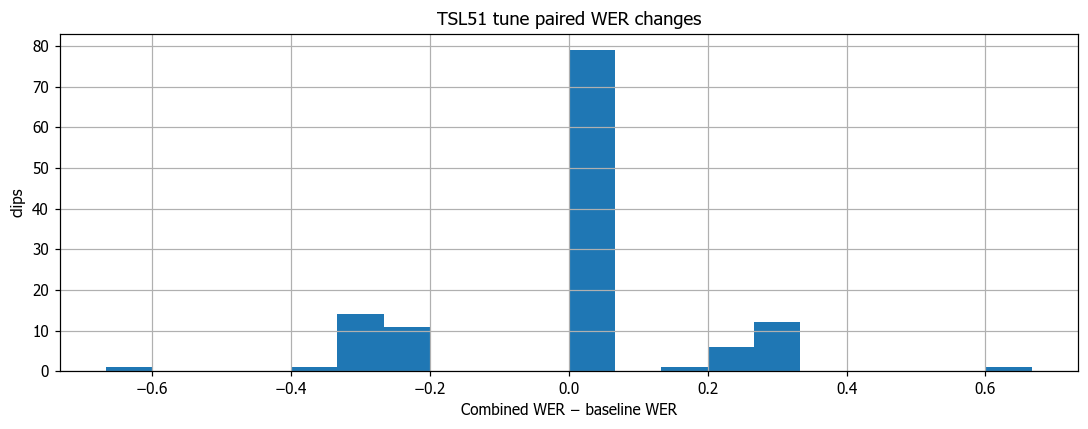

**กราฟ:** ซ้ายศูนย์=WER ลดลง ขวาศูนย์=แย่ลง ไม่ได้พิสูจน์ขอบเขต segment ถูก เพราะยังไม่มี human timed labels

,clip,mode,WER,S,D,I,recall1,recall5,n_pred,n_ref,inference_s,ref,hyp
0,t51s:กรุงเทพ_var_1__น้อง_var_1__เที่ยว_var_1__ชอบ_var_1_no_space_0,baseline,0.250,1,0,0,0.750,0.750,4,4,4.543,กรุงเทพ | น้อง | เที่ยว | ชอบ,กรุงเทพ | น้อง | หนึ่ง | ชอบ
1,t51s:กรุงเทพ_var_1__น้อง_var_1__เที่ยว_var_1__ชอบ_var_1_no_space_0,combined_without_csls,0.500,2,0,0,0.500,1.000,4,4,5.846,กรุงเทพ | น้อง | เที่ยว | ชอบ,กรุงเทพ | เดิน | ไม่รู้ | ชอบ
2,t51s:กรุงเทพ_var_1__น้อง_var_1__เที่ยว_var_1__ชอบ_var_1_no_space_1,combined_without_csls,0.250,1,0,0,0.750,1.000,4,4,5.186,กรุงเทพ | น้อง | เที่ยว | ชอบ,หนังสือ | น้อง | เที่ยว | ชอบ
3,t51s:กรุงเทพ_var_1__น้อง_var_1__เที่ยว_var_1__ชอบ_var_1_no_space_1,baseline,0.500,2,0,0,0.500,1.000,4,4,2.694,กรุงเทพ | น้อง | เที่ยว | ชอบ,กรุงเทพ | น้องชาย | หนึ่ง | ชอบ
4,t51s:กรุงเทพ_var_1__น้อง_var_1__เที่ยว_var_1__ชอบ_var_1_no_space_2,baseline,0.500,2,0,0,0.500,1.000,4,4,2.746,กรุงเทพ | น้อง | เที่ยว | ชอบ,กรุงเทพ | น้องชาย | หนึ่ง | ชอบ
...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,t51s:ไข่_var_2__แม่_var_1__กิน_var_1__ชอบ_var_1_no_space_0,baseline,0.250,0,1,0,0.750,0.750,3,4,1.196,ไข่ | แม่ | กิน | ชอบ,ไข่ | แม่ | ชอบ
248,t51s:ไข่_var_2__แม่_var_1__กิน_var_1__ชอบ_var_1_no_space_1,baseline,0.500,2,0,0,0.750,0.750,4,4,1.191,ไข่ | แม่ | กิน | ชอบ,ไข่ | แม่ | ชอบ | ฉัน
249,t51s:ไข่_var_2__แม่_var_1__กิน_var_1__ชอบ_var_1_no_space_1,combined_without_csls,0.250,0,0,1,1.000,1.000,5,4,2.001,ไข่ | แม่ | กิน | ชอบ,ไข่ | แม่ | กิน | ชอบ | ฉัน
250,t51s:ไข่_var_2__แม่_var_1__กิน_var_1__ชอบ_var_1_no_space_2,combined_without_csls,0.250,0,1,0,0.750,0.750,3,4,2.175,ไข่ | แม่ | กิน | ชอบ,ไข่ | แม่ | ชอบ


**ผลรายประโยคครบ:** reference gloss เป็นลำดับจริงใน dataset; พิกัด alignment เดิมไม่ถูกใช้เป็น human ground truth เพื่อสร้าง F1

In [7]:
RUN_TSL51 = False  # เปิด True เพื่อรัน tune ใหม่ทั้ง 126 ประโยค
if RUN_TSL51:
    de.launch_tsl51()
de.show_tsl51()

# สรุปผลจริง: Decoder tuning — 19 ตุลาคม 2026

## สิ่งที่รัน
- Boom: 6 คลิปจริง × 9 configurations = 54 inference runs; CSLS ข้ามเพราะไม่มี hub vector
- TSL51: tune 126 ประโยค × baseline/combined = 252 inference runs; test 126 ประโยคไม่ได้เปิดใช้
- ไม่แก้โมเดล bank หรือ production spotting.json

## ผลเทียบ baseline → combined_without_csls
| ชุด | Macro WER เดิม | ใหม่ | ดีขึ้น/เท่าเดิม/แย่ลง |
|---|---:|---:|---|
| Boom 6 คลิป (text WER) | 1.714 | 1.636 | 3 / 2 / 1 |
| TSL51 tune (gloss WER) | 0.402 | 0.385 | 27 / 79 / 20 |

นิยาม WER ของสองชุดต่างกัน จึงไม่เทียบขนาดค่าข้าม dataset โดยตรง. WER > 1 เกิดได้เมื่อคำแทรกมาก ไม่ใช่ accuracy ติดลบ

## Trade-offs ของ TSL51
- Substitutions: 153 → 136
- Deletions: 12 → 20
- Insertions: 8 → 9
- Presence Recall@1: 0.618 → 0.636
- Presence Recall@5: 0.895 → 0.874
- Mean absolute count error: 0.159 → 0.230
- Mean inference: 1.712 → 2.796 วินาที/คลิป (ไม่รวม extraction; single run, มีงานรันพร้อมกัน)
- Paired mean WER delta = -0.0168; clip-bootstrap 95% CI [-0.0515, +0.0173] คร่อมศูนย์ ไม่ยืนยันความเหนือกว่าทั่วไป

## ข้อสรุป
ยังไม่ควรนำชุดรวมเข้า production: ลด substitution แต่ทำ deletion และ count error แย่ลง ต้องแยกผล exact_rescore ออกจากเกณฑ์กรองความยาว/activation บน tune ต่อไป คง test ไว้สำหรับ configuration ที่ล็อกแล้ว

บน Boom หลายค่าปรับเดี่ยวไม่เปลี่ยนผล; exact_rescore ดีขึ้น 3 คลิปและแย่ลง 2 คลิป ส่วน activity060 ดีขึ้น 1 คลิป ไม่มีคลิปแย่ลงในชุดเล็กนี้ จึงยังไม่ใช่หลักฐานเพียงพอเลือกตัวเดียวทั่วระบบ

## ข้อจำกัด vocabulary
conversation vocabulary ไม่มี แอบ หรือ แอบชอบ แม้มี ฉัน/ชอบ/คุณ การจูน decoder จึงไม่สามารถให้ประโยคตัวอย่างนี้ครบทุกคำด้วยตัวเลือกปัจจุบัน ต้องแก้ vocabulary/bank ในการทดลองแยก

## เปิดผล
Notebook: decoder_tuning.ipynb
Boom: outputs/20261019_153342/
TSL51 tune: outputs/tsl51_tune_20261019_153646/
มี raw predictions, effective config, provenance, metrics และผลรายคลิปสำหรับตรวจย้อนกลับ


## Visual comparison: ภาพและคลิปจริง

ภาพกลาง segment พร้อม Top-5 cosine และ p_correct จากผลเดิม เทียบ combined_without_csls บนคลิปเดียวกัน ไม่มีการรันโมเดลใหม่หรือแก้ผลทำนาย ตัวอย่าง TSL51 เป็นภาพเคลื่อนไหวจาก pose ของ tune set ไม่ใช่ RGB เลือกตัวอย่างแรกที่ WER ดีขึ้นและแย่ลงตามลำดับไฟล์ ไม่ได้คัดเฉพาะผลดี

คำทำนายที่เปลี่ยนยังไม่ถือว่าถูกขึ้นหากไม่มี temporal ground truth; p_correct เป็น calibrator เดิม ไม่มีการยืนยัน calibration หลังจูน

In [8]:
# ตั้ง True เฉพาะเมื่อต้องการสร้าง visual ใหม่จาก saved predictions
REBUILD_VISUALS=False
if REBUILD_VISUALS:
    import subprocess
    subprocess.run([str(ex.PYTHON),str(HERE/'visual_results.py')],cwd=ROOT,env=ex.subprocess_environment(),check=True)


### ฉันยังลืมคุณไม่ได้
RGB video

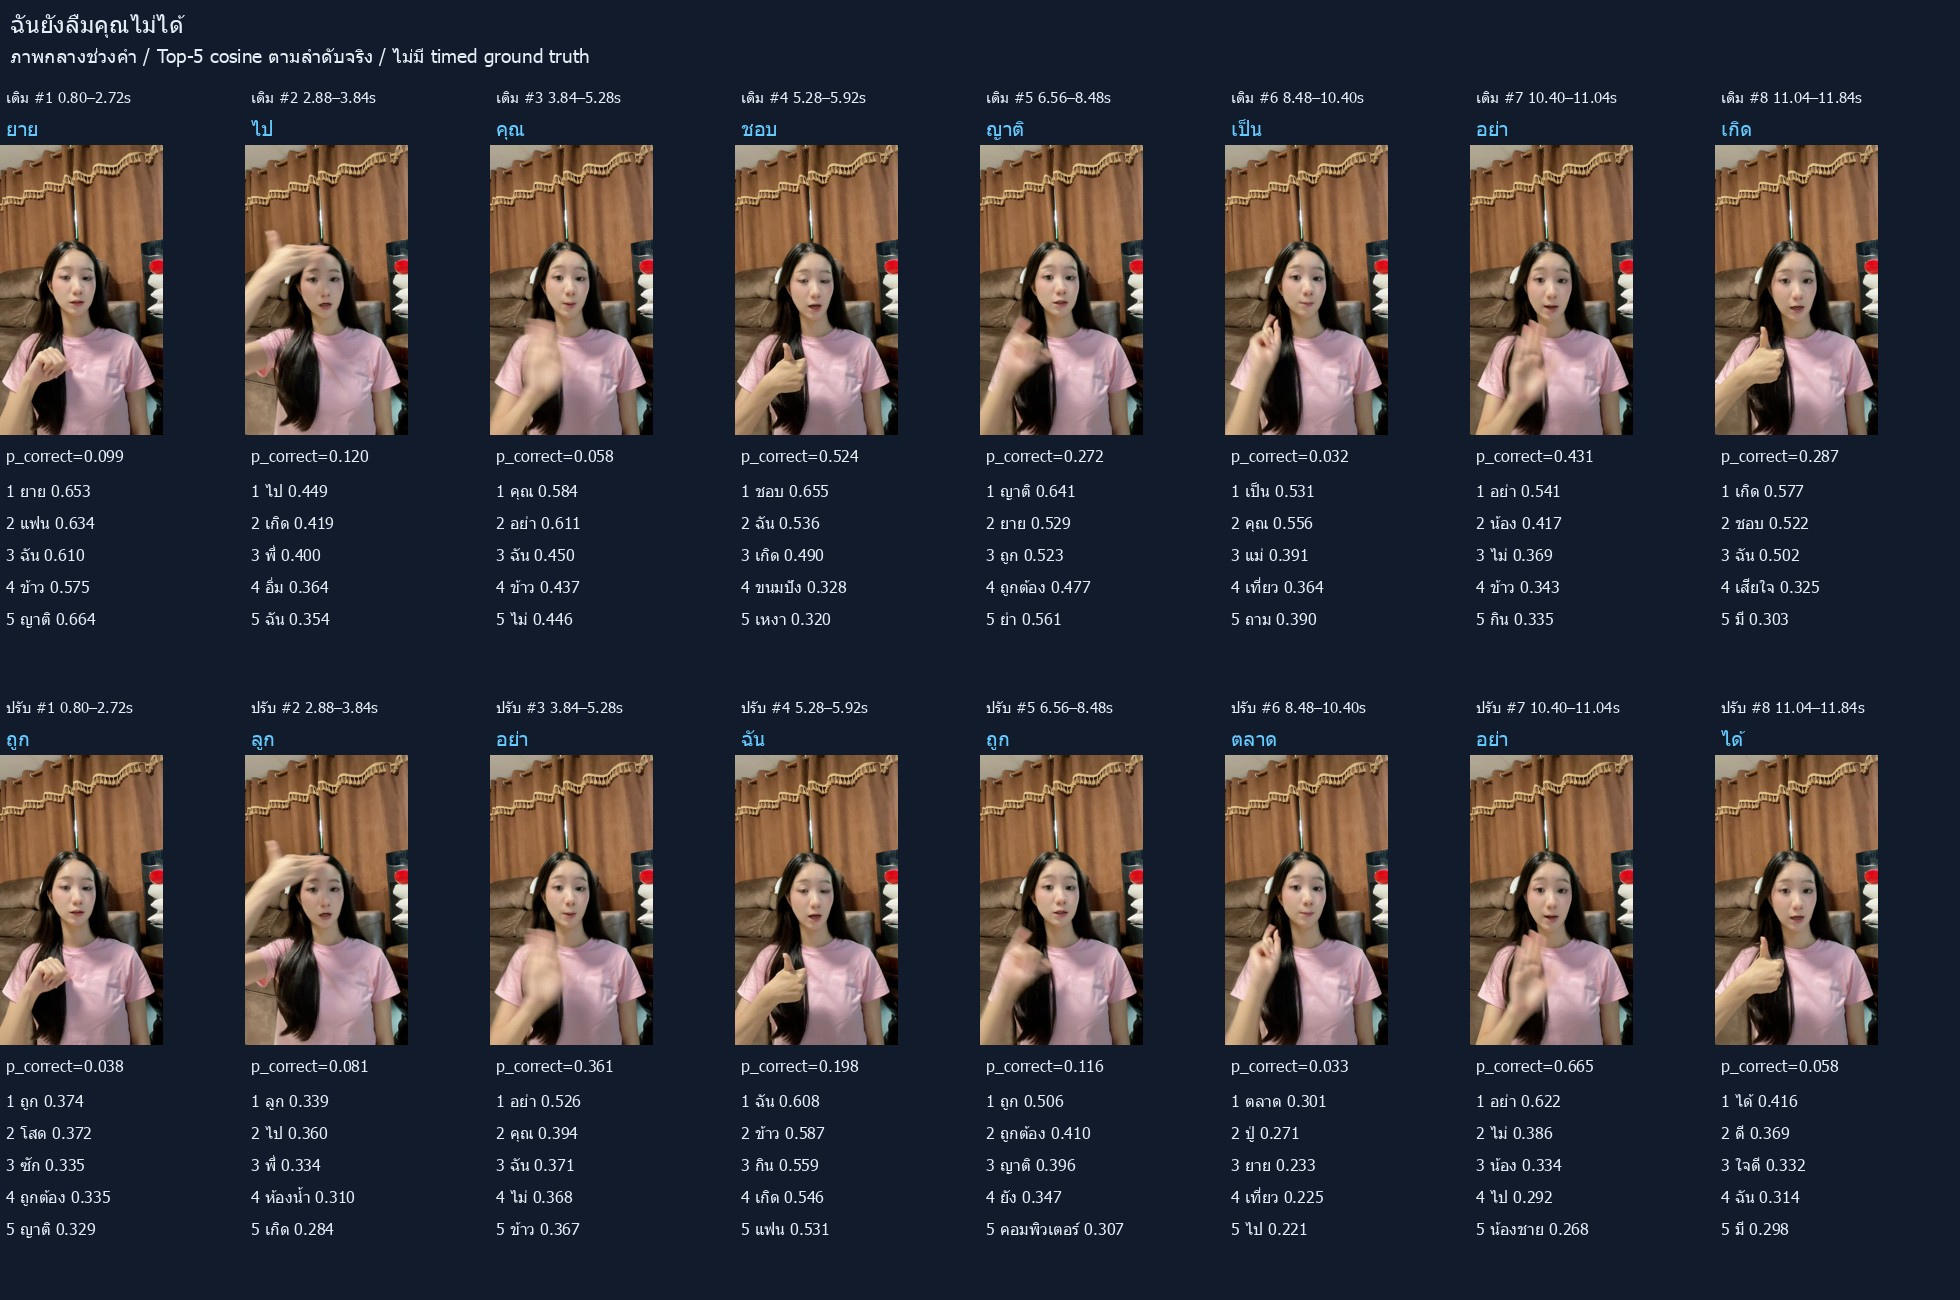

### ฉันแอบชอบคุณ
RGB video

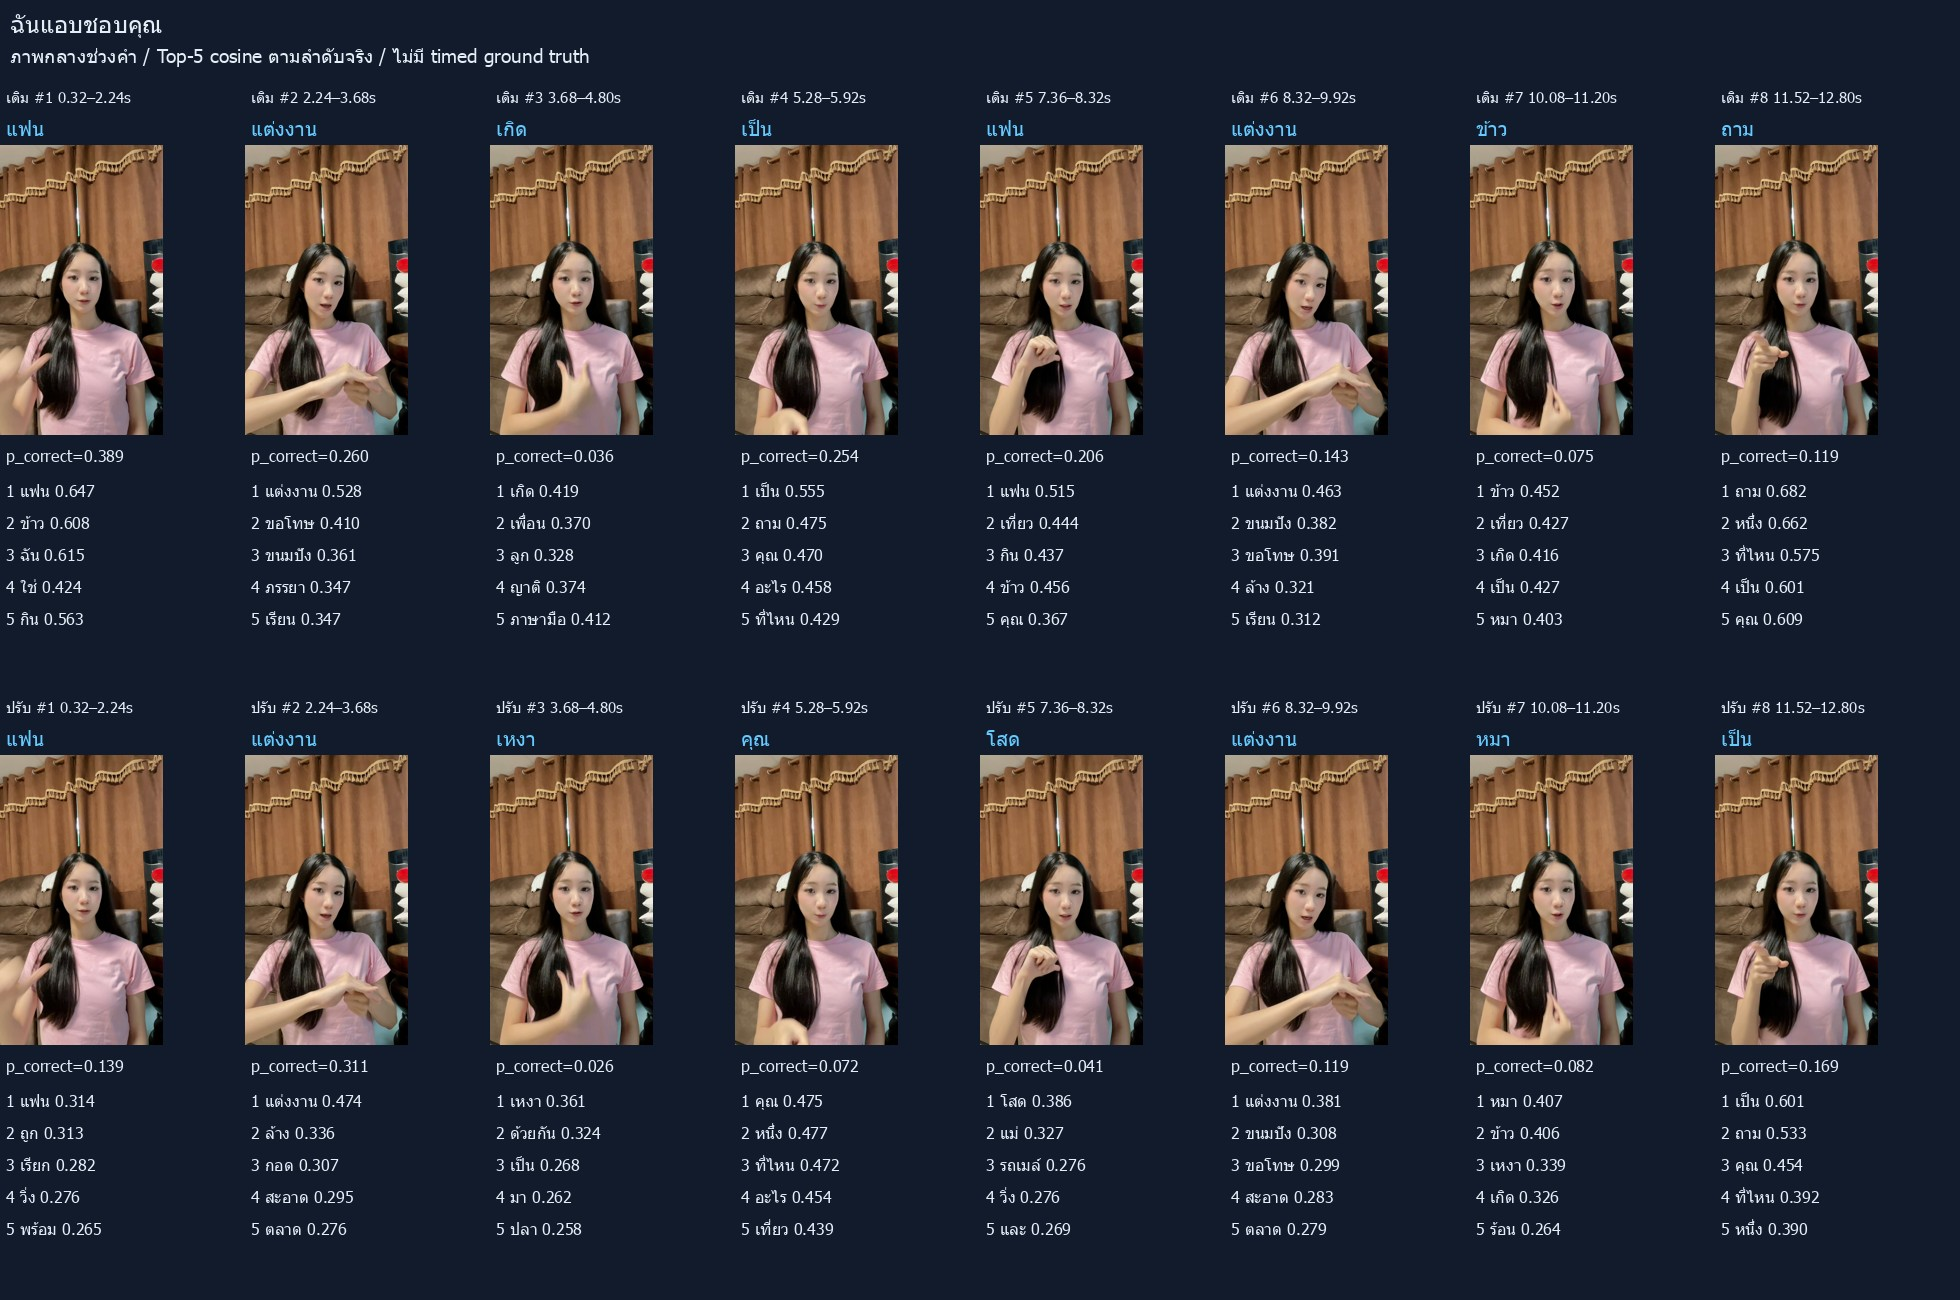

### ตอนนี้กำลังเรียนภาษา
RGB video

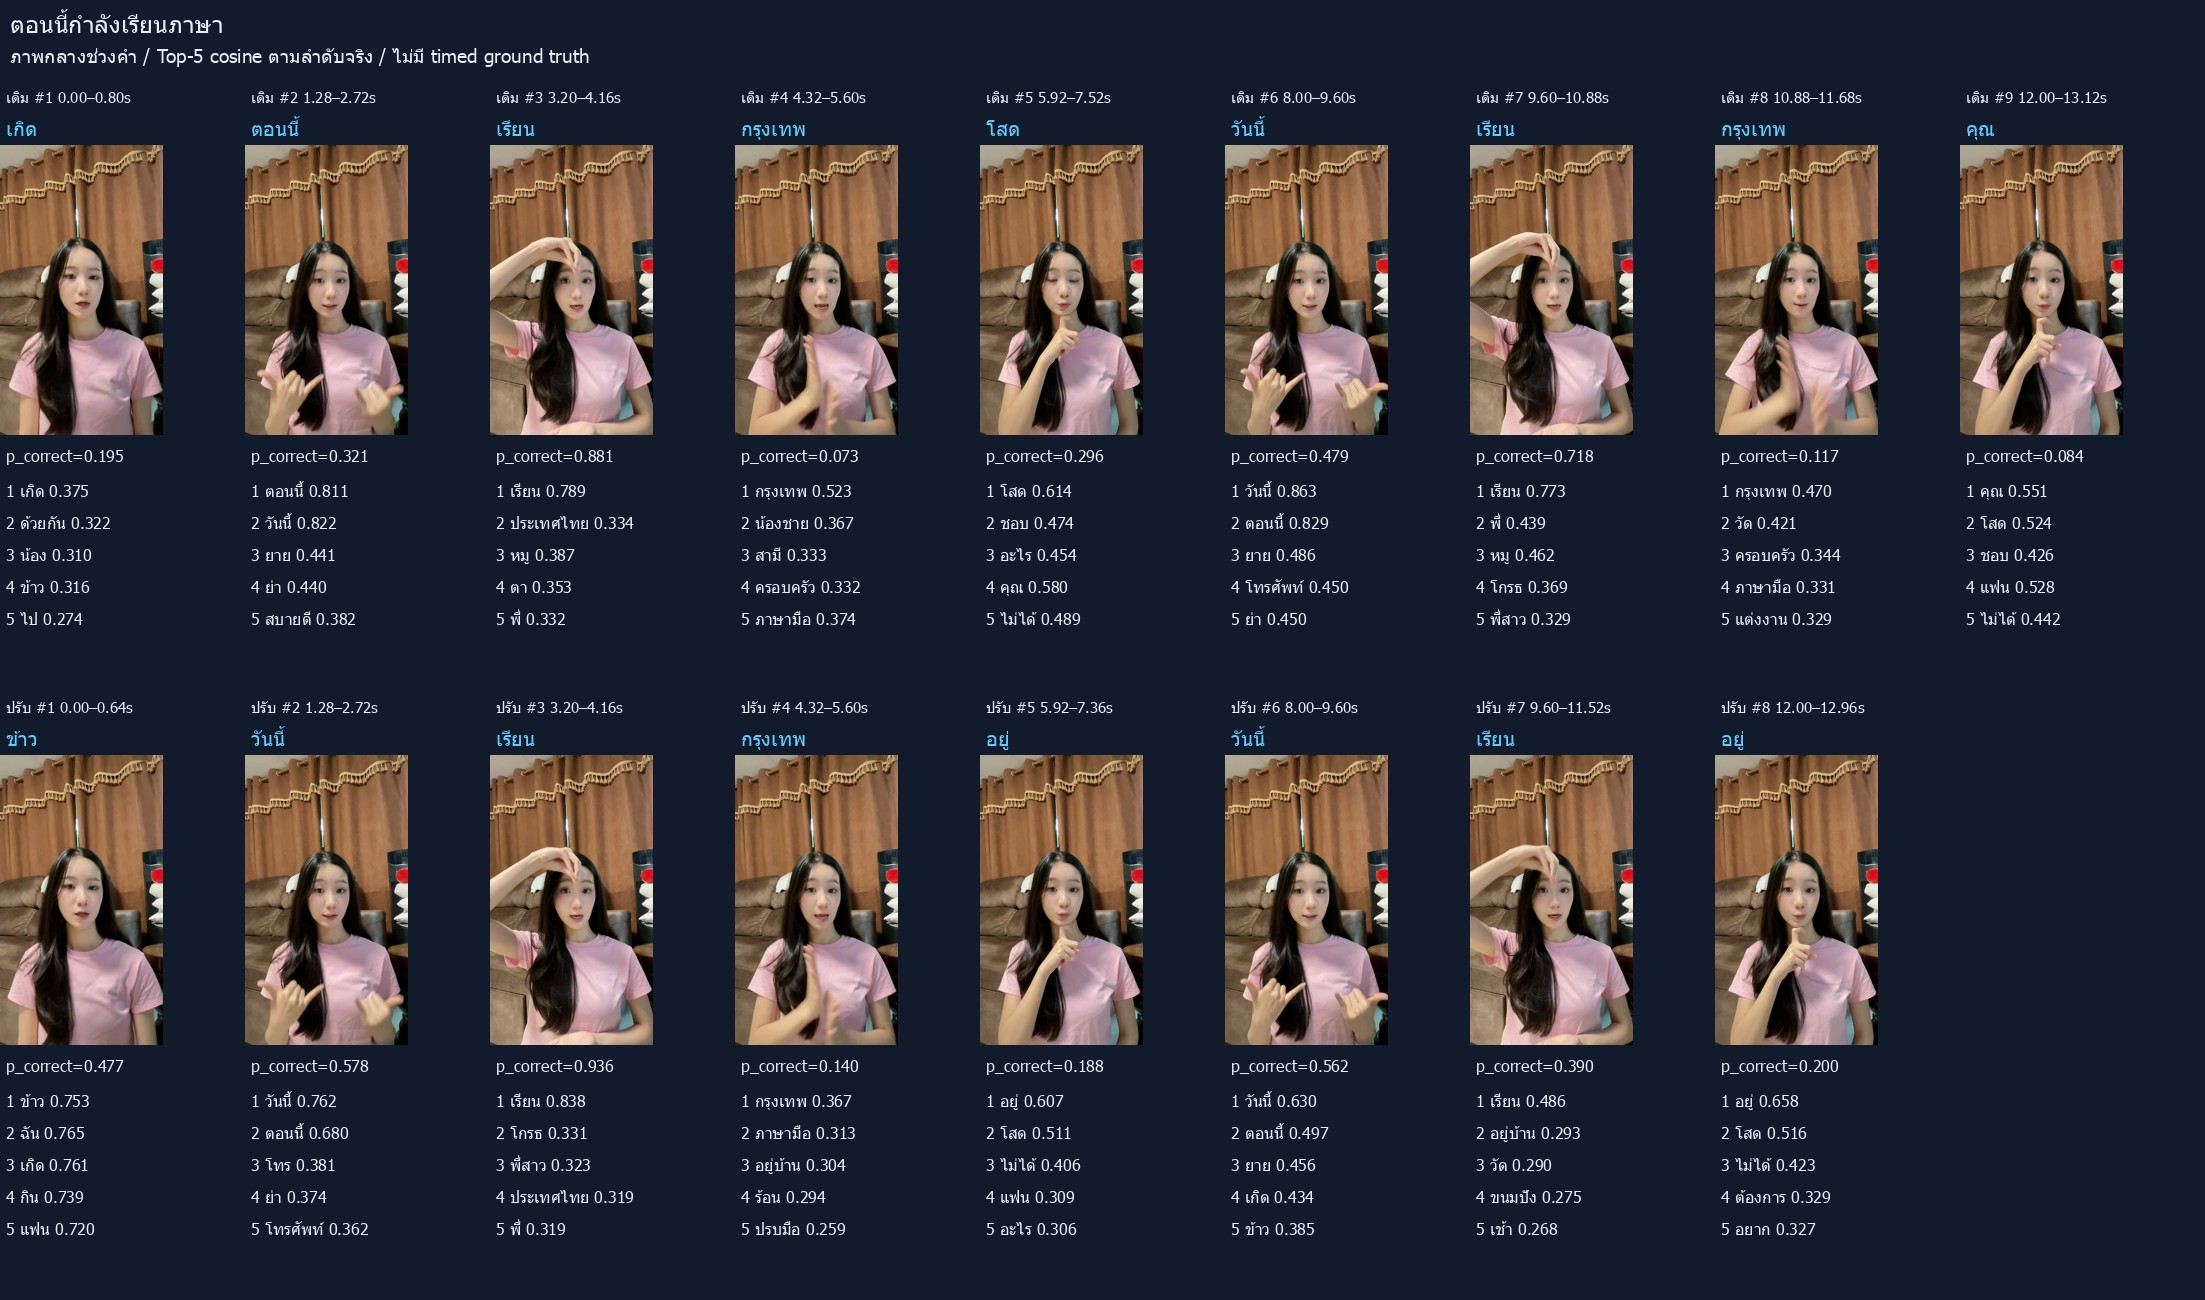

### มีอะไรให้ฉันช่วยไหม
RGB video

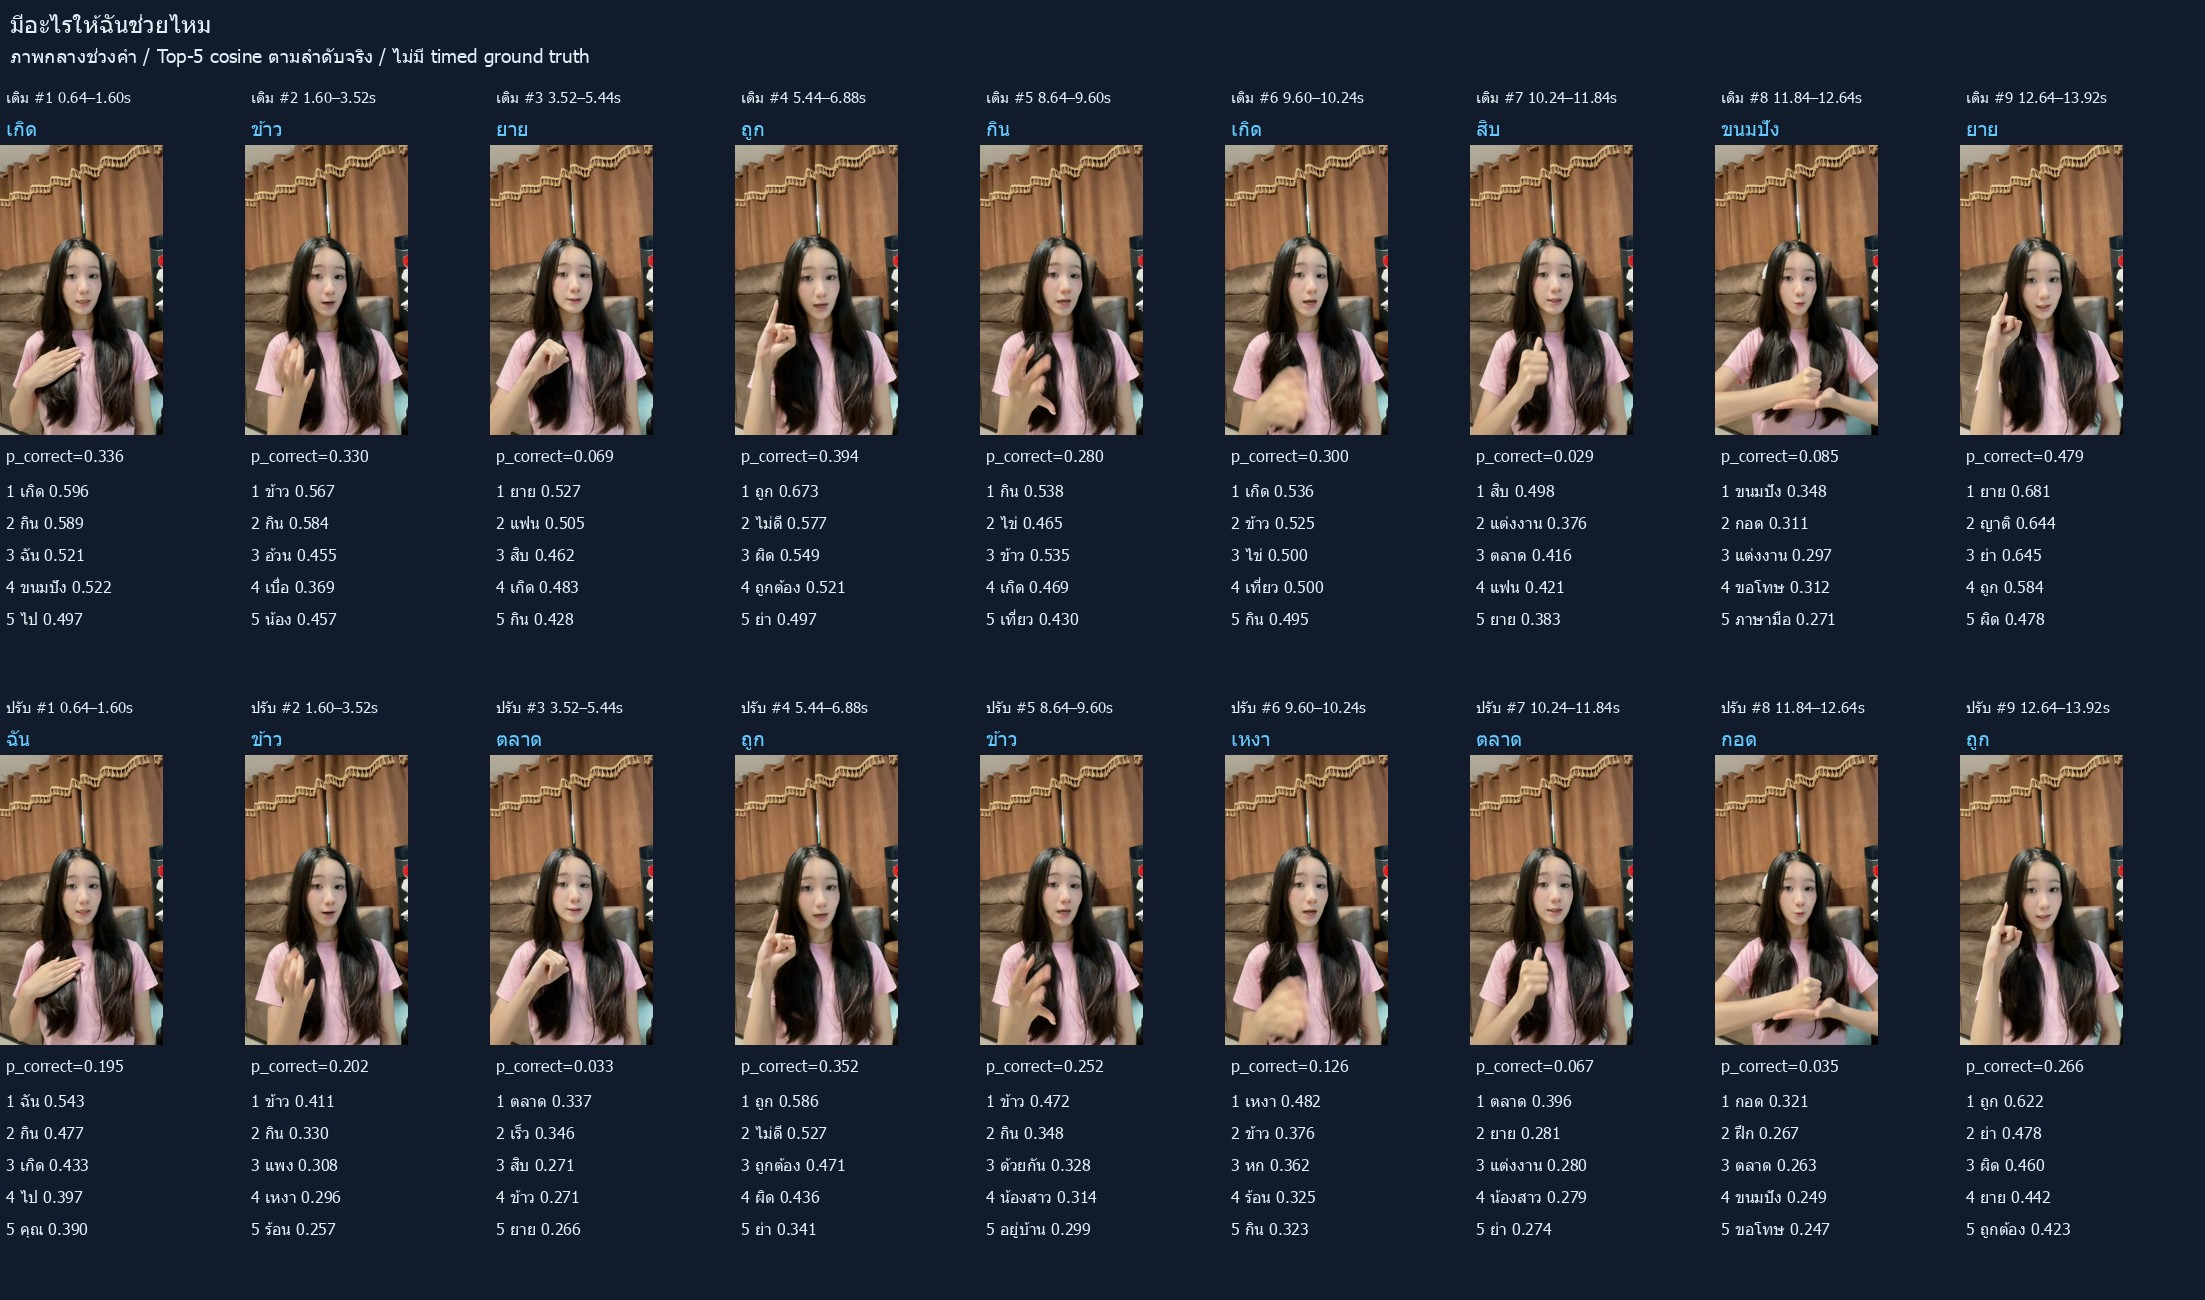

### เราจะเป็นเพื่อนกันตลอดไป
RGB video

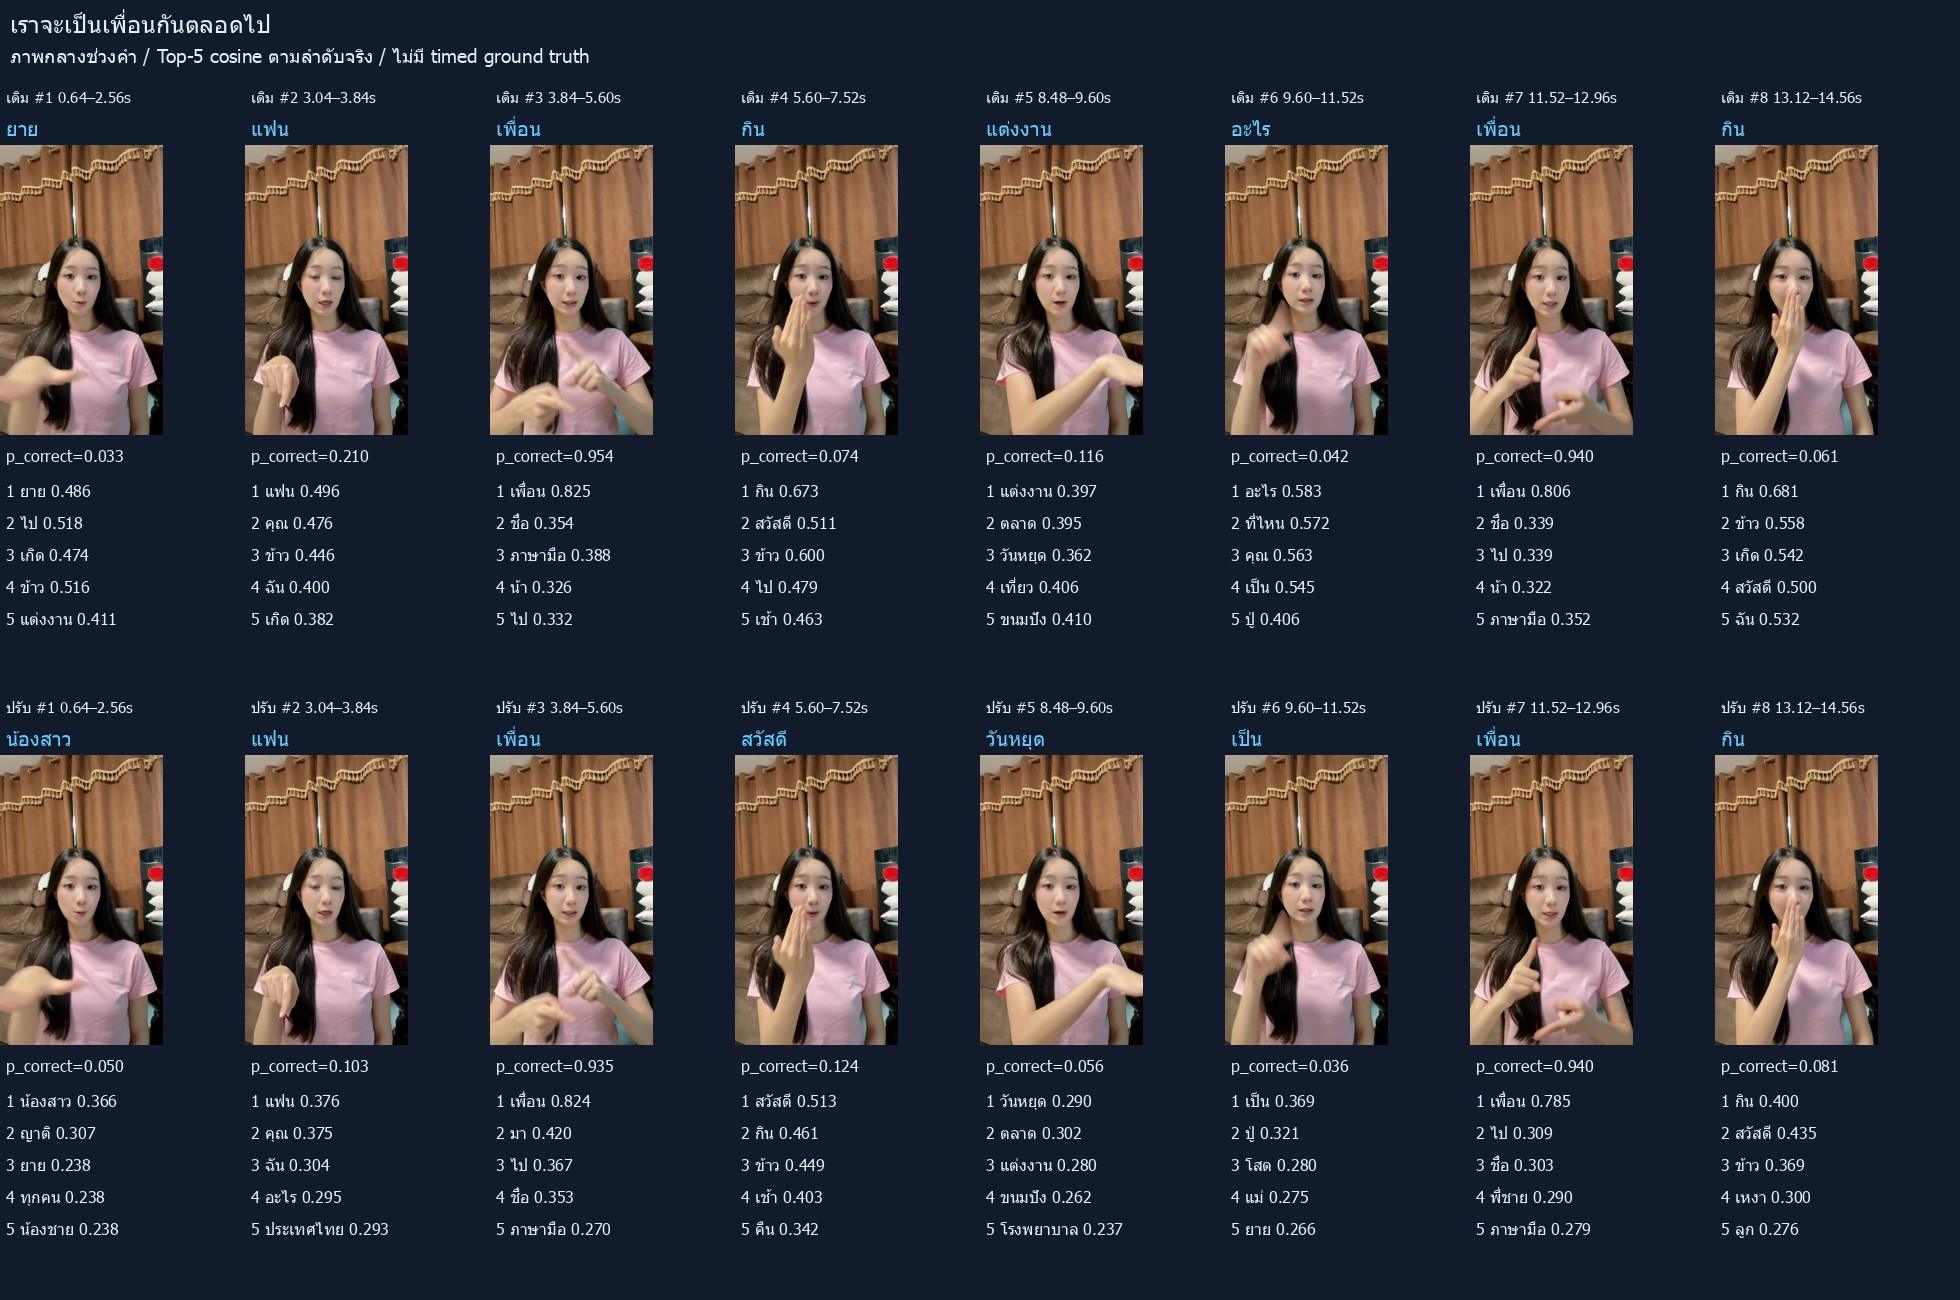

### เล่นเกมส์กันไหม
RGB video

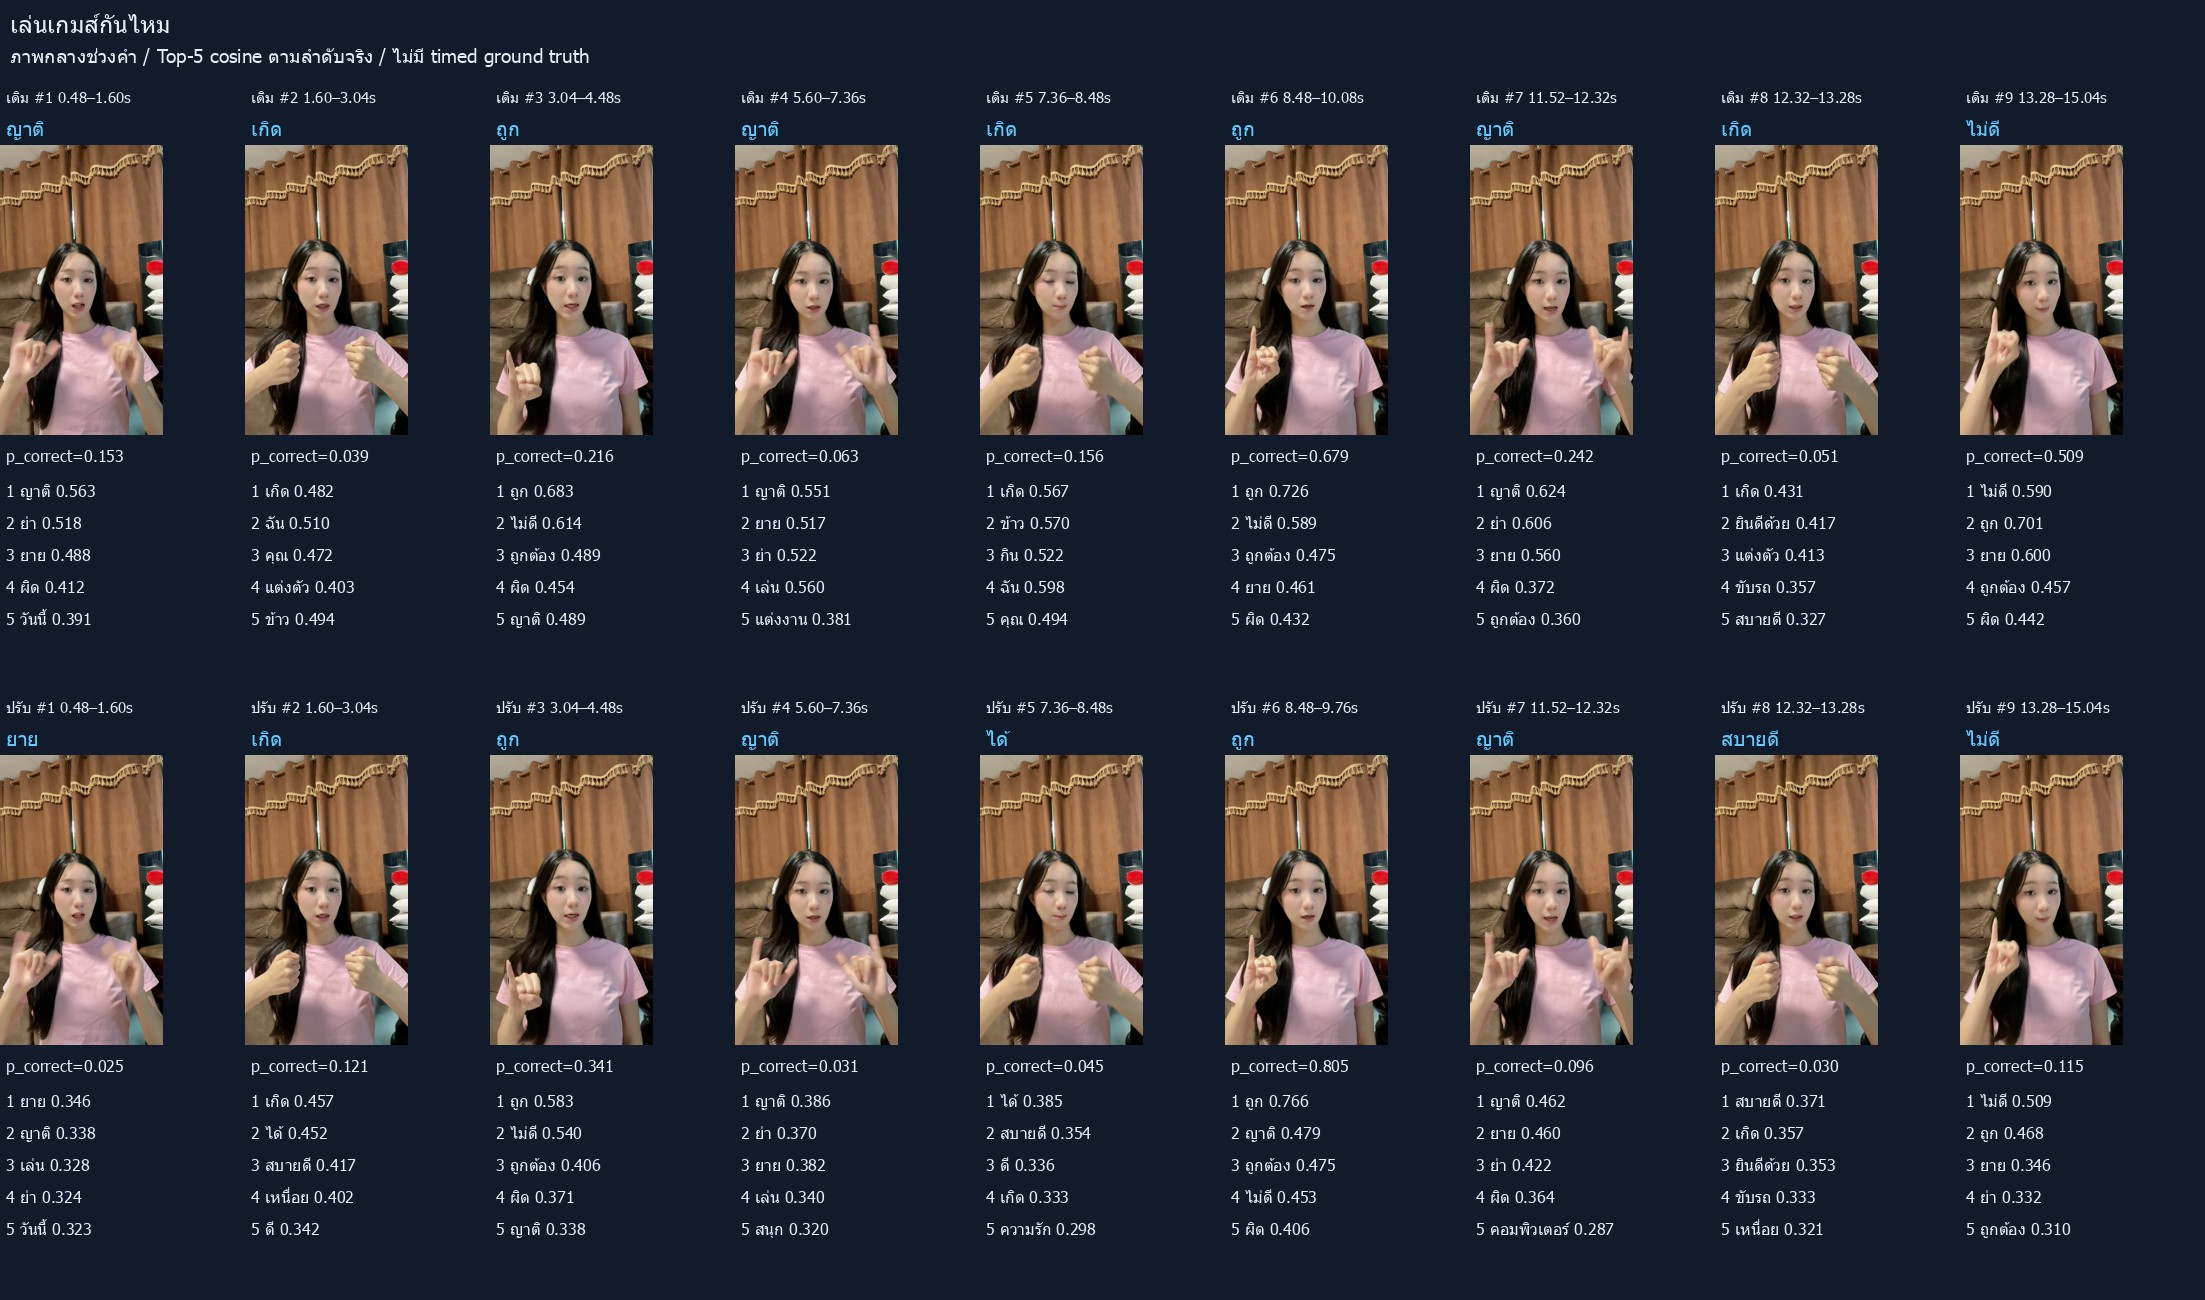

### TSL51 improved | GT: กรุงเทพ น้อง เที่ยว ชอบ
pose; WER 0.5 → 0.25

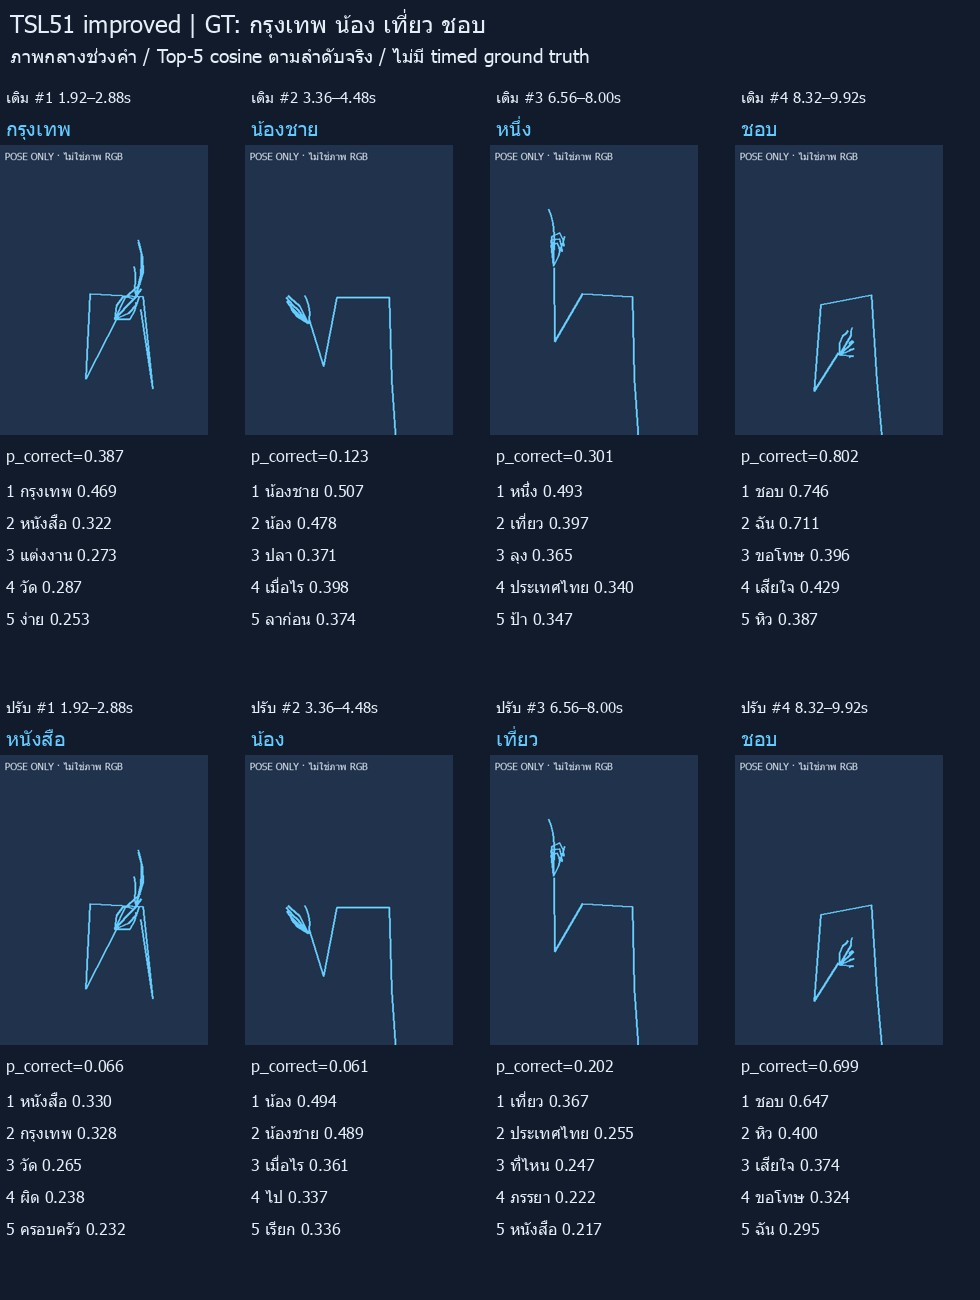

### TSL51 worsened | GT: กรุงเทพ น้อง เที่ยว ชอบ
pose; WER 0.25 → 0.5

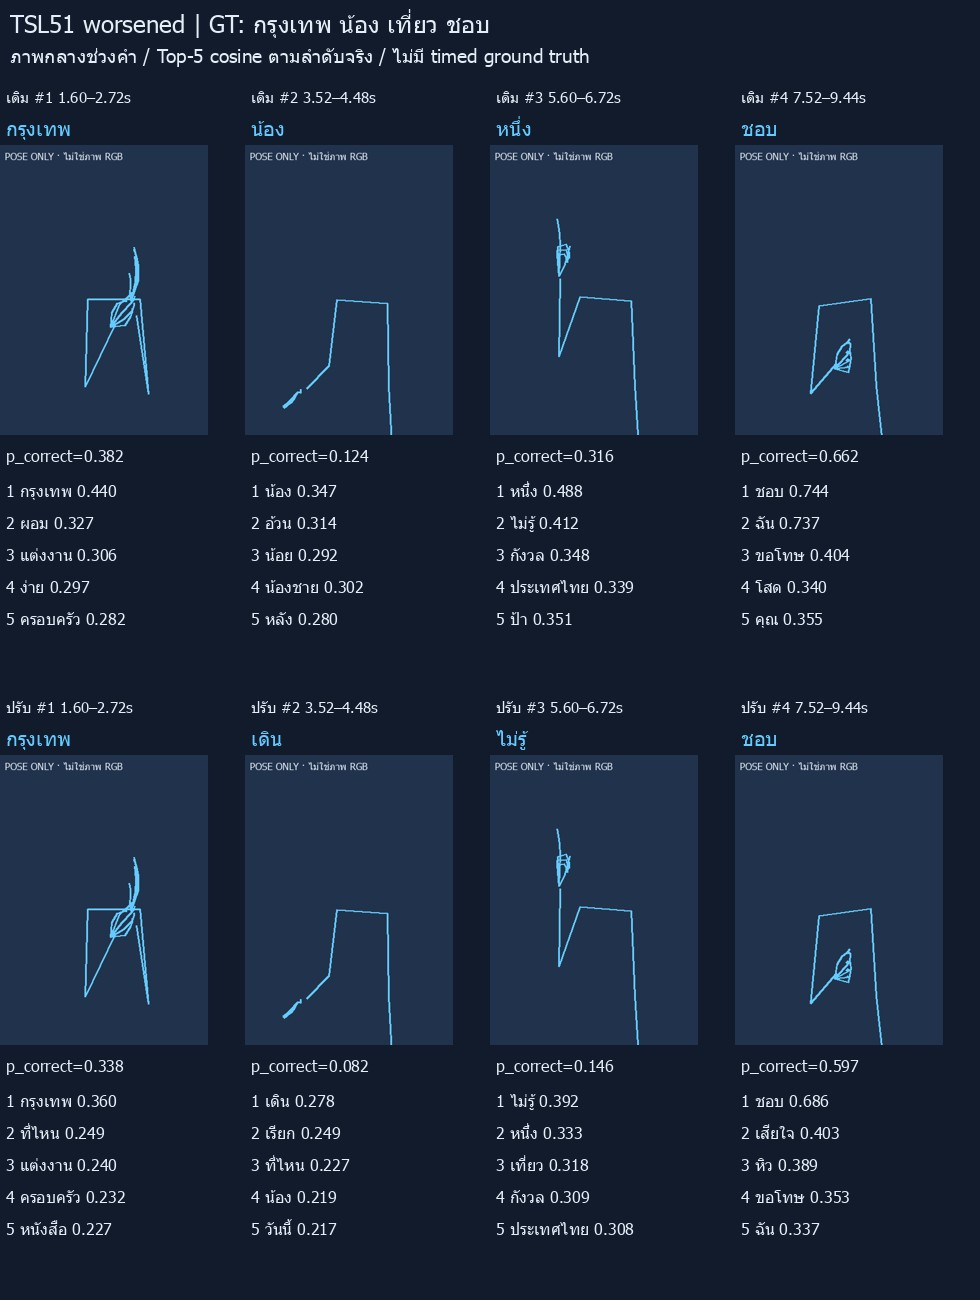

In [9]:
from IPython.display import display, Video, Image, Markdown
import json
VIS=HERE/'outputs/visuals'
visual_manifest=json.loads((VIS/'manifest.json').read_text())
for name,title,kind in visual_manifest['items']:
    display(Markdown(f'### {title}\n{kind}'))
    display(Video(str(VIS/f'{name}.mp4'), embed=True, width=950))
    display(Image(filename=str(VIS/f'{name}.jpg'),width=1100))


## A–C: ตรวจ leakage, ทดสอบตัวกรอง และ audit คู่คำ (v7.2)

รอบนี้ไม่เทรน ไม่แก้ bank หรือ default ของแอป ใช้โมดูลจริงและรายงานจากไฟล์ผลจริง ข้อมูล test ที่ผู้ใช้รายงานแล้วไม่นับเป็น untouched holdout; การรันสุดท้ายต้อง freeze ค่าไว้ก่อน

In [ ]:
import audit_report as ar
import audit_experiments as ae
from IPython.display import display, Markdown
display(ar.table('grammar_overlap.csv'))
display(Markdown(str(ex.read(ar.OUT/'provenance.json'))))

**อ่านตาราง:** same role template บอกการซ้ำโครงสร้าง ส่วน same word sequence บอกการซ้ำเฉลยประโยค การตรงกับทุกข้อมูลในสคริปต์ยืนยัน text leakage แต่ไม่พิสูจน์ว่าฝึกภาพจาก test

In [ ]:
display(ar.table('grammar_cv_summary.csv').sort_values(['version','macro_WER']))
ar.plot_grid()

**อ่านกราฟ:** original อาจได้ประโยชน์จากเฉลยชุดประเมิน ส่วน template_cv กัน role-template ที่กำลังสอบออกทั้งหมด ค่า CV ที่เลือกดีที่สุดยังเป็นคะแนนที่ใช้เลือก hyperparameter ไม่ใช่ผลยืนยันอิสระ

In [ ]:
display(ar.table('grammar_cv_changes.csv').query("version == 'template_cv'").sort_values('visual_drop',ascending=False).head(40))

**อ่านคำที่เปลี่ยน:** visual_drop สูงแปลว่าเลือกคำที่ cosine ต่ำกว่า เป็นคิวให้ตรวจท่าจริง ไม่ใช่หลักฐานว่า grammar ทำผิด new_in_reference ไม่ใช่ temporal ground truth

In [ ]:
for folder in sorted(ar.OUT.glob('*x')):
    if (folder/'summary.csv').exists():
        display(Markdown('### '+folder.name))
        display(ar.table(str(folder.relative_to(ar.OUT)/'summary.csv')))
        display(ar.table(str(folder.relative_to(ar.OUT)/'paired_ci.csv')))

**อ่านผล:** เทียบ S/D/I กับ grammar_original ภายในชุดเดียวกัน ถ้า CI คร่อม 0 ให้สรุปว่าไม่มีนัยสำคัญ เกณฑ์ accepted มีผลต่อ filter และ grammar ด้วยใน v7.2 จึงไม่รับประกันว่าเปลี่ยนเฉพาะข้อความที่แสดง latency ที่ใช้ cache ไม่ใช่ end-to-end benchmark

In [ ]:
display(ar.table('pair_summary.csv'))
ar.enrich_sources()
display(ar.table('review_priority.csv').head(30))

**อ่าน audit:** cosine มาจาก encoder เดิมของช่วงคำ auto-aligned บน tune ต้องตรวจขอบเขตท่าและต้นทางก่อนสรุป label noise ไม่ลบตัวอย่างจาก bank อัตโนมัติ

In [ ]:
display(ar.table('bank_inventory.csv'))
display(ar.table('pair_cosines.csv'))
display(ar.table('nearest_neighbours.csv'))

**ไฟล์ตรวจด้วยตา:** เปิด outputs/audit_v72/review.html เพื่อดู path RGB/pose และจำนวนครั้งที่เป็นเพื่อนบ้านของคำผิด ไฟล์ RGB ที่ไม่อยู่ในเครื่องแสดงเป็น path เท่านั้น

In [ ]:
# Opt-in only: no model runs on ordinary Run All.
RUN_AUDIT=False
RUN_TUNE=False
if RUN_AUDIT:
    subprocess.run([str(ex.PYTHON),str(HERE/'audit_experiments.py'),'--grammar-audit','--bank-audit'],cwd=ROOT,env=ex.subprocess_environment(),check=True)
if RUN_TUNE:
    subprocess.run([str(ex.PYTHON),str(HERE/'full_audit_run.py'),'--run','--dataset','tune'],cwd=ROOT,env=ex.subprocess_environment(),check=True)
# Test is deliberately not triggered here; full_audit_run.py requires --final-test and has a one-run lock.

### ภาพตรวจ bank และ coverage ของ query
ภาพเป็นพิกัดจริงจากช่วง tune และคลิปเพื่อนบ้าน ไม่ใช่ RGB ไม่ใช้ยืนยันว่า label ผิดโดยลำพัง


In [ ]:
display(ar.query_coverage().round(3))
from IPython.display import Image
review_images=pd.read_csv(ar.OUT/'pose_review/index.csv')
display(review_images)
for file in review_images.image.head(3):
    display(Image(filename=file,width=1000))


**ตีความ:** query_fraction เป็น coverage ของ auto-alignment ไม่ใช่ความแม่นของขอบเขต ค่า cosine ตรวจด้วย eval bank เป็นหลัก ส่วน production bank อาจมีตัวอย่างจาก recording เดียวกันตามคอลัมน์ same_source_recording


In [ ]:
for image in ar.comparison_plots():
    display(Markdown('### '+image.parent.name))
    display(Image(filename=str(image),width=1100))


**ข้อจำกัด:** accepted_correct_ordered ใช้การจับคู่ลำดับคำ ไม่ใช่การตรวจเวลาโดยคน; Boom ยังไม่มี accepted precision ที่ตรวจรับรอง และไม่มี Segment F1 จาก human ground truth จึงไม่ใส่ตัวเลขแทน ค่าความเร็วประมวลผลที่มี cache ไม่ใช้เทียบ latency ของแอปจริง
